# Aufgabe 1: NLP-Techniken anwenden, um eine Textsammlung zu analysieren

## Konfiguration der Laufzeitumgebung

In [1]:
# Meldungen

# Deaktivierung der Tokenizer-Parallelisierung zur Vermeidung von Prozesskonflikten während der BERTopic-Ausführung.
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"



## Datensatzverarbeitung (engl. dataset pipeline)

In [2]:
# Datensatzverarbeitung (engl. dataset pipeline)
# Pakete werden über environment.yml installiert.
# Diese Zelle nicht ausführen, um die Conda-Umgebung nicht zu überschreiben.

### Datensatzsichtung (engl. dataset inspection)
Die Datensatzsichtung untergliedert sich in Datenstrukturanalyse, Explorative Datenanalyse und die Datensatzaufbereitung.

#### Datenstrukturanalyse (engl. data structure analysis)
Die Stukturiertung des Datensatzes wird durch die Datenstrukturanalyse erkundet. Der Datensatz `complaints_data.csv` wird eingelesen und die Struktur der Daten untersucht. Es werden die ersten 10 Zeilen sowie die wichtigsten Metadaten (Spalten, Datentypen, Anzahl der Werte) angezeigt, um einen ersten Überblick über den Aufbau des Datensatzes zu erhalten.

In [3]:
# ============================================================
# Datenstrukturanalyse (engl. data structure analysis)
# ============================================================
print("=== Datenstrukturanalyse (engl. data structure analysis) ===\n")

import pandas as pd
from IPython.display import display

df1 = pd.read_csv('../datasets/complaints_data.csv')

print("--- Vorschau der ersten 10 Zeilen ---")
display(df1.head(10))

print("\n--- Übersicht der Datenstruktur ---")
df1.info()

=== Datenstrukturanalyse (engl. data structure analysis) ===

--- Vorschau der ersten 10 Zeilen ---


,author,posted_on,rating,text
0,"Alantae of Chesterfeild, MI","Nov. 22, 2016",1,I used to love Comcast. Until all these consta...
1,"Vera of Philadelphia, PA","Nov. 19, 2016",1,I'm so over Comcast! The worst internet provid...
2,"Sarah of Rancho Cordova, CA","Nov. 17, 2016",1,If I could give them a negative star or no sta...
3,"Dennis of Manchester, NH","Nov. 16, 2016",1,I've had the worst experiences so far since in...
4,"Ryan of Bellevue, WA","Nov. 14, 2016",1,Check your contract when you sign up for Comca...
5,"Terri of Mobile, AL","Nov. 9, 2016",1,Thank God. I am changing to Dish. They gave me...
6,"Kellie of Salt Lake City, UT","Nov. 9, 2016",1,I Have been a long time customer and only have...
7,"Kathleen of New Haven, CT","Nov. 6, 2016",2,There is a malfunction on the DVR manager whic...
8,"Shira of Bloomfield, NJ","Nov. 5, 2016",1,Charges overwhelming. Comcast service rep was ...
9,"Kristy of Alpharetta, GA","Nov. 2, 2016",1,"I have had cable, DISH, and U-verse, etc. in t..."



--- Übersicht der Datenstruktur ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5659 entries, 0 to 5658
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   author     5659 non-null   object
 1   posted_on  5659 non-null   object
 2   rating     5659 non-null   int64 
 3   text       5629 non-null   object
dtypes: int64(1), object(3)
memory usage: 177.0+ KB


#### Dateninhaltsanalyse (engl. data content analysis)
Im Rahmen der Dateninhaltsanalyse wird eine explorative Datenanalyse (EDA) des gewählten Datensatzes durchgeführt. Hierbei werden die stukturiert und unstrukturiert vorliegende Informationen für die weitere Verarbeitung identifiziert.

##### Analyse der strukturierten Daten (engl. analysis of structured data)
Analyse der strukturiert vorliegenden Daten aus den Spalten "author" "posted_on" und "rating".

In [4]:
# ============================================================
### Ortsdatenanalyse (engl. location data analysis)
# ============================================================
print("=== Ortsdatenanalyse (engl. location data analysis) ===\n")

import pandas as pd
df = pd.read_csv('../datasets/complaints_data.csv')

#### Extrahieren der Bundesstaaten aus der "author"-Spalte
df["state"] = df["author"].str.extract(r",\s*([A-Z]{2})\s*$", expand=False)                 # Spalte "state" für Visualisierung in Datennachverarbeitung

##### State-Codes: alle extrahierten (2 Großbuchstaben am Ende)
all_extracted = df["state"].dropna().unique()

##### gültige State-Codes: US-Bundesstaaten (50 Staaten + DC / 51 Referenz)
all_states_set = {
    "AL","AK","AZ","AR","CA","CO","CT","DE","FL","GA","HI","ID","IL","IN","IA",
    "KS","KY","LA","ME","MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ",
    "NM","NY","NC","ND","OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VT",
    "VA","WA","WV","WI","WY","DC"
}
##### ungültige State-Codes
invalid_states = [s for s in all_extracted if s not in all_states_set]
print(f"Bundesstaaten ungültig: {len(invalid_states)} \n{sorted(invalid_states)}\n")

all_states = pd.Series(list(all_states_set))

valid_states_only = df["state"].dropna()
valid_states_only = valid_states_only[valid_states_only.isin(all_states_set)]

#### Verteilung der Beschwerden nach den Bundesstaaten
##### Bundesstaaten MIT Beschwerden
print(f"Bundesstaaten mit Beschwerden: {len(valid_states_only.value_counts())}")
for state, count in valid_states_only.value_counts().items():
    print(f"{state}: {count}")

##### Bundesstaaten OHNE Beschwerden
missing_states = all_states_set - set(valid_states_only.unique())
print(f"\nBundesstaaten ohne Beschwerden: {len(missing_states)}\n",
    sorted(missing_states), sep='')

### Kontrollrechnung (51 Bundesstaaten insgesamt)
print(f"\nKONTROLLE: {len(valid_states_only.value_counts())} + {len(missing_states)} = {len(valid_states_only.value_counts()) + len(missing_states)}")

=== Ortsdatenanalyse (engl. location data analysis) ===

Bundesstaaten ungültig: 3 
['BC', 'ON', 'PE']

Bundesstaaten mit Beschwerden: 46
FL: 778
CA: 554
GA: 414
IL: 378
PA: 326
NJ: 278
TX: 274
MI: 266
TN: 244
MD: 238
WA: 215
VA: 215
MA: 184
CO: 182
IN: 144
MN: 108
OR: 100
CT: 75
UT: 62
AL: 55
NH: 45
DC: 41
SC: 41
DE: 40
NM: 38
MS: 35
NY: 32
LA: 28
AZ: 22
WV: 21
KY: 21
AR: 19
VT: 12
OH: 12
MO: 12
WI: 9
ME: 7
NC: 7
NV: 5
KS: 4
ID: 2
ND: 2
HI: 2
AK: 1
WY: 1
NE: 1

Bundesstaaten ohne Beschwerden: 5
['IA', 'MT', 'OK', 'RI', 'SD']

KONTROLLE: 46 + 5 = 51


- Zeitdaten (engl. time data analysis)

In [5]:
# ============================================================
# Zeitdatenanalyse (engl. time data analysis)
# ============================================================
print("=== Zeitdatenanalyse (engl. time data analysis) ===\n")

import pandas as pd

df = pd.read_csv('../datasets/complaints_data.csv')

# Datum konvertieren
df['date'] = pd.to_datetime(df['posted_on'], format='mixed', errors='coerce')

# Zeitraum
print("*** Zeitraum ***")
print(f"Erstes Datum:   {df['date'].min().strftime('%Y-%m-%d')}")
print(f"Letztes Datum:  {df['date'].max().strftime('%Y-%m-%d')}")
total_days = (df['date'].max() - df['date'].min()).days
years = total_days // 365
remaining_days = total_days % 365
print(f"Zeitraum:       {years} Jahre, {remaining_days} Tage ({total_days} Tage)")

# Datumsmerkmale extrahieren
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()
df['weekday'] = df['date'].dt.day_name()

# Monatskategorie für korrekte Sortierung
months_order = pd.date_range(start='2026-01-01', end='2026-12-01', freq='MS').strftime('%B').tolist()
df['month_name'] = pd.Categorical(df['month_name'], categories=months_order, ordered=True)

# DataFrame chronologisch sortieren
df = df.sort_values(['year', 'month']).reset_index(drop=True)

# Verteilungen
print("\n*** Verteilung der Beschwerden ***")
print("\nVerteilung pro Jahr:")
print(df['year'].value_counts().sort_index())

print("\nVerteilung pro Monat:")
print(df['month_name'].value_counts().sort_index())

print("\nVerteilung pro Wochentag:")
print(df['weekday'].value_counts())

=== Zeitdatenanalyse (engl. time data analysis) ===

*** Zeitraum ***
Erstes Datum:   2000-07-31
Letztes Datum:  2016-11-22
Zeitraum:       16 Jahre, 118 Tage (5958 Tage)

*** Verteilung der Beschwerden ***

Verteilung pro Jahr:
year
2000       1
2001       2
2002       1
2003       6
2004      10
2006      34
2007     106
2008     441
2009     462
2010     415
2011     357
2012     418
2013     313
2014     770
2015    1477
2016     846
Name: count, dtype: int64

Verteilung pro Monat:
month_name
January      485
February     476
March        441
April        369
May          394
June         461
July         529
August       540
September    507
October      526
November     505
December     426
Name: count, dtype: int64

Verteilung pro Wochentag:
weekday
Wednesday    993
Tuesday      960
Thursday     861
Monday       820
Friday       802
Saturday     659
Sunday       564
Name: count, dtype: int64


- Bewertungen (engl. rating data analysis)

In [6]:
# NumPy wird über environment.yml installiert.

=== Bewertungsdatenanalyse (engl. rating data analysis) ===

*** Absolute Verteilung der Bewertungen ***

rating
1    3734
0    1560
2     260
3      54
5      32
4      19
Name: count, dtype: int64
*** Relative Verteilung der Bewertungen ***

rating
1    65.98%
0    27.57%
2     4.59%
3     0.95%
5     0.57%
4     0.34%
Name: proportion, dtype: object


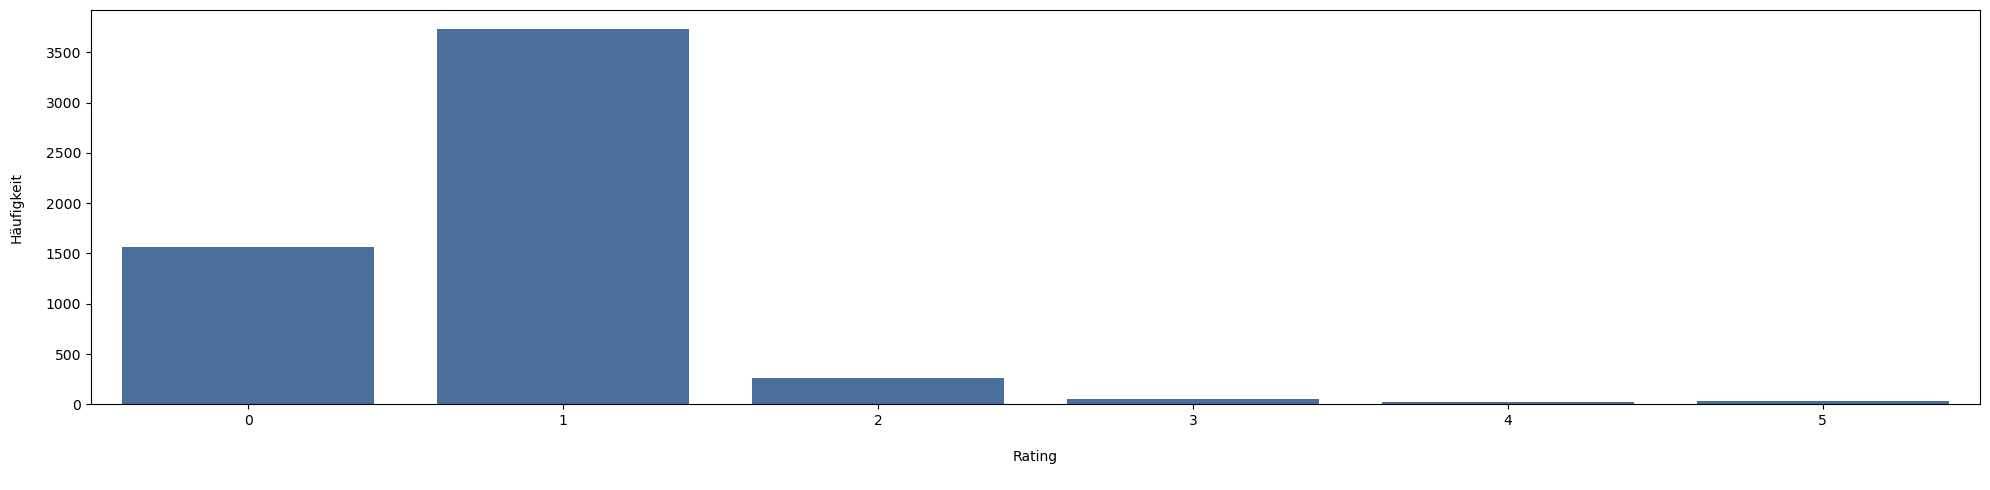

In [7]:
# ============================================================
# Bewertungsdatenanalyse (engl. rating data analysis)
# ============================================================
print("=== Bewertungsdatenanalyse (engl. rating data analysis) ===\n")

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

df = pd.read_csv('../datasets/complaints_data.csv')


# Absolute Verteilung
print("*** Absolute Verteilung der Bewertungen ***\n")
verteilung = df['rating'].value_counts()
print(verteilung)

# Prozentuale Verteilung
print("*** Relative Verteilung der Bewertungen ***\n")
prozente = (df['rating'].value_counts(normalize=True) * 100).round(2).astype(str) + '%'
print(prozente)

# Balkendiagramm der Verteilung
result = df['rating'].value_counts().sort_index().reset_index()
result.columns = ['Rating', 'Anzahl']

fig = plt.figure(figsize=(20, 5))
fig.set_dpi(100)
ax = sns.barplot(data=result, x='Rating', y='Anzahl', color='#3b6ea8')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: f"{int(y)}"))
plt.xlabel('\nRating\n')
plt.ylabel('Häufigkeit\n')
plt.tight_layout()
plt.show()

##### Fehlwertanalyse (engl. missing value analysis)
Bei der Fehlwertanalyse werden leere Zellen (NaNs/NaTs) im Datensatz und fehlerhaft erhobene Daten identifiziert. ////// VORSICHT TEIL DER DATENSATZVALIDIERUNG

In [8]:
# ============================================================
# Fehlwertanalyse (engl. missing value analysis)
# ============================================================
print("=== Fehlwertanalyse (engl. missing value analysis) ===\n")

import pandas as pd
df = pd.read_csv('../datasets/complaints_data.csv')

# Fehlwerterfassung
## Fehlwerte in den strukturierte Daten
fehlende_author = df[df['author'].isna()]
fehlende_posted_on = df[df['posted_on'].isna()]
fehlende_rating = df[df['rating'].isna()]

## ungültige US-Bundesstaaten ['BC', 'ON', 'PE']
df["state"] = df["author"].str.extract(r",\s*([A-Z]{2})\s*$", expand=False)
all_states_set = {
    "AL","AK","AZ","AR","CA","CO","CT","DE","FL","GA","HI","ID","IL","IN","IA",
    "KS","KY","LA","ME","MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ",
    "NM","NY","NC","ND","OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VT",
    "VA","WA","WV","WI","WY","DC"
}
invalid_states = df[~df["state"].isin(all_states_set) & df["state"].notna()]
## Fehlwerte ungültige Bundesstaaten
print("*** Fehlwerterfassung ungültige Bundesstaaten ***\n")
print(invalid_states[['author', 'text']].to_string(index=True, max_colwidth=100))

print(f"\n    Zeilen mit ungültigen US-Bundesstaaten: {len(invalid_states)}")

## Fehlwerte in den unstrukturierte Daten
fehlende_text = df[df['text'].isna()]

# Fehlwertausgabe
## Fehlwertausgabe stukturierte Daten
print("\n*** Fehlwerterfassung strukturierte Daten ***")
print(f"    Fehlwerte in 'author': {len(fehlende_author)}")
print(f"    Fehlwerte in 'posted_on': {len(fehlende_posted_on)}")
print(f"    Fehlwerte in 'rating': {len(fehlende_rating)}")
## Fehlwertausgabe unstukturierte Daten
print("\n*** Fehlwerterfassung unstrukturierte Daten ***")
print(f"    Fehlwerte in 'text': {len(fehlende_text)}")

=== Fehlwertanalyse (engl. missing value analysis) ===

*** Fehlwerterfassung ungültige Bundesstaaten ***

                            author                                                                                                 text
1586  Sylvain of San Francisco, BC  If you sign with Comcast, it is very likely you'll have to deal with their customer service - an...
2015        Joshua of Portland, ON  Most recently, Zach, Technician #** came out at my request and gave me a new X1 set top box and ...
3195         Susan of Broomall, PE  I tried calling Comcast to resolve an issue with my ON Demand, I waited almost an hour, was disc...

    Zeilen mit ungültigen US-Bundesstaaten: 3

*** Fehlwerterfassung strukturierte Daten ***
    Fehlwerte in 'author': 0
    Fehlwerte in 'posted_on': 0
    Fehlwerte in 'rating': 0

*** Fehlwerterfassung unstrukturierte Daten ***
    Fehlwerte in 'text': 30


##### Analyse der unstrukturierten Daten (engl. analysis of unstructured data)
Analyse der unstrukturiert vorliegenden Daten aus den Spalten "text".

- Duplikaterkennung (engl. duplicate detection)

In [9]:
# ============================================================
# Duplikaterkennung (engl. duplicate detection)
# ============================================================
print("=== Duplikaterkennung (engl. duplicate detection) ===\n")

import pandas as pd

# Datensatz laden
df = pd.read_csv('../datasets/complaints_data.csv')

duplikate = df[df.duplicated(keep=False)]

### Duplikate nach Zeilen
print("*** Duplikate pro Zeile ***")
print(f"Gesamtzeilen:                    {len(df):,}")
print(f"Doppelte Gesamtzeilen:           {df.duplicated().sum():,}")
print(f"Duplikat-Anteil:                 {(df.duplicated().sum() / len(df) * 100):.2} %")
print()

### Duplikate darstellen
print("*** Darstellung: Duplikate pro Zeile ***\n")
pd.set_option('display.max_colwidth', None)  # Unbegrenzte Breite
pd.set_option('display.width', 500)          # Gesamtbreite erhöhen
print(df[df.duplicated(keep=False)])

print(f"\nAnzahl doppelter Zeilen: {len(duplikate)}")

### Duplikate nach Spalten
print("\n*** Duplikate pro Spalte ***")
print(f"Doppelte author-Spalten:         {df.duplicated(subset=['author']).sum():,}")
print(f"Doppelte text-Spalten:           {df.duplicated(subset=['text']).sum():,}")
print()

### Duplikate nach Spalte "text
print("*** Duplikate nach Spalte 'text' ***\n")
duplikate_text = df[df.duplicated(subset=['text'], keep=False)]
print(duplikate_text)
print(f"\nAnzahl doppelter text-Zeilen: {len(duplikate_text)}")

=== Duplikaterkennung (engl. duplicate detection) ===

*** Duplikate pro Zeile ***
Gesamtzeilen:                    5,659
Doppelte Gesamtzeilen:           1
Duplikat-Anteil:                 0.018 %

*** Darstellung: Duplikate pro Zeile ***

                          author     posted_on  rating                                                                                                                                                                                                                                                                                                                                                                                                                                          text
1397  Jennifer of Wheatridge, CO  Nov. 2, 2016       1  The services provided by Comcast are ridiculous. You pay lots of money for no adequate service. Everything keeps dropping from the cable to the internet to the phone on important calls. It takes hours to get the custom

- Textlängenanalyse (engl. text length analysis)</br>
Im Rahmen der Textlängenanalyse werden die Beschwerdelängen anhand der Zeichenfrequenz durchgeführt. Hierzu werden die Beschwerden statistisch auf Zeichen und Satzebene ausgewertet und die Ergebnisse für nachfolgende Schritte visualisiert.

=== Textlängenanalyse (engl. text length analysis) ===



,Anzahl Zeichen,Anzahl Sätze
Mittelwert,"1.233,22","15,25"
Minimum,"0,00","0,00"
Median,"864,00","11,00"
Maximum,"93.136,00","1.706,00"


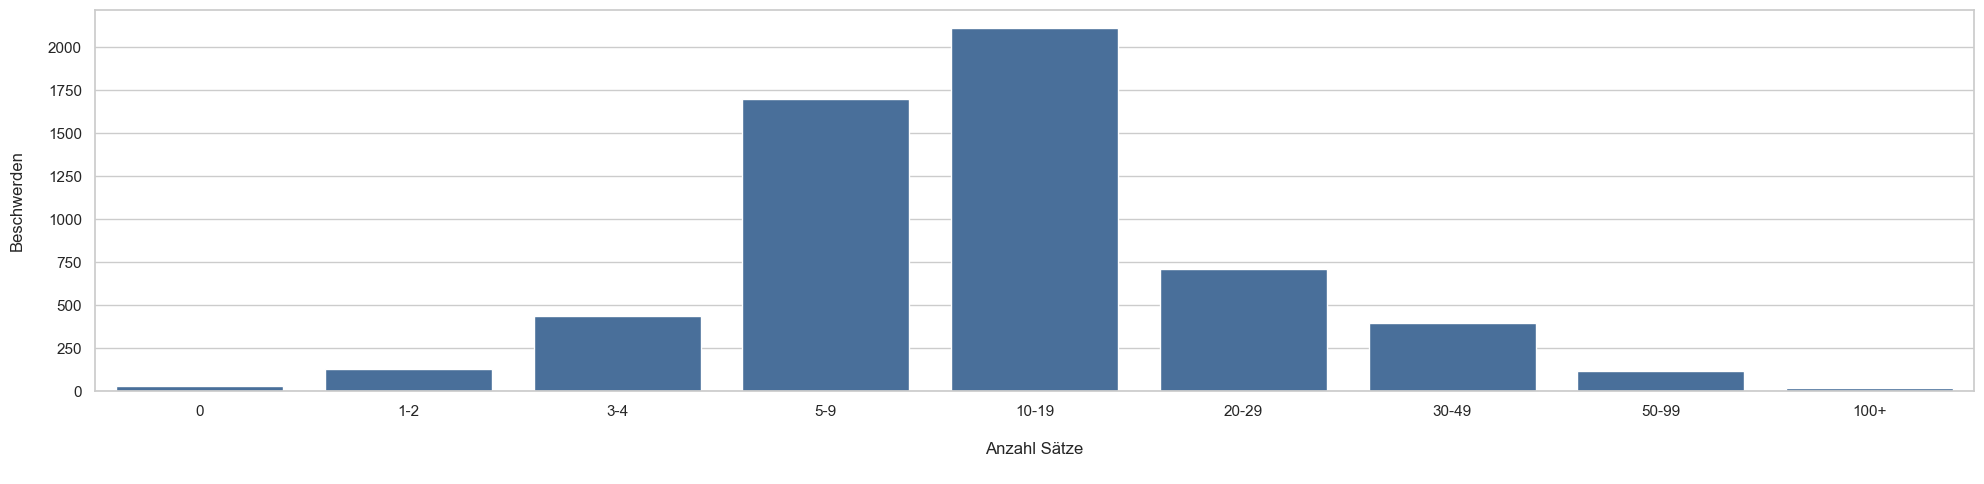


*** längste Bewertungen (Top 5) ***


,text_length,saetze,text
Zeile-Nr.,,,
5237,93136,1706,"Channel 65 did not work since about August 1, 2008 on all non-cable box TVs Low or no signals since September 15, 2008. Technicians at house about once a week since October 1, 2008. Specific Dates In ..."
5386,26593,357,"As a Taxpaying, American Combat Veteran, I will swear under oath this is a true story & the story before you has been condensed believe it or not. Today is 07/30/08 and I have been a Comcast customer..."
5362,24039,289,I originally signed up with Adelphia Cable in 2002 for digital cable service. The service was great! No problems with reception or customer service. About two years ago Comcast Cable Company ...
5465,17350,151,Starting in the beginning of May 2008 my husband and I got divorced. We moved into a new house and the first thing we did was call comcast. They came out the first week of May and installed our tv and...
5358,14740,163,"I am a former customer of Comcast as I am appalled by the very poor customer service that Comcast has rendered to me as a customer. I moved to my current location on July 4, 2008. Two weeks prior t..."


In [10]:
# ============================================================
# Textlängenanalyse (engl. text length analysis)
# ============================================================
print("=== Textlängenanalyse (engl. text length analysis) ===\n")

import pandas as pd
import re
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

# Datensatz laden
df3 = pd.read_csv('../datasets/complaints_data.csv')

# Längenberechnungen
text_series = df3['text'].fillna('').astype(str)
df3['text_length'] = text_series.str.len()
df3['saetze'] = text_series.apply(
    lambda x: len([s for s in re.split(r'[.!?]+', x) if s.strip()])
)

def format_de(value, decimals=2):
    formatted = f"{value:,.{decimals}f}"
    return formatted.replace(",", "X").replace(".", ",").replace("X", ".")


# ********************************************************************
# Beschwerdelängenanalyse (engl. complaint length analysis)  
# ********************************************************************

# Kurzstatistiken (Tabelle)
short_stats = df3[['text_length', 'saetze']].describe().round(2)
short_stats = short_stats.drop(index=['count', 'std', '25%', '75%'])

# Spaltennamen auf Deutsch umbenennen
short_stats.columns = ['Anzahl Zeichen', 'Anzahl Sätze']

# Index auf Deutsch umbenennen
short_stats.index = ['Mittelwert', 'Minimum', 'Median', 'Maximum']

# Colormap 
from matplotlib.colors import LinearSegmentedColormap
colors_blue = ['#e6f2ff', '#3b6ea8']
cmap_blue = LinearSegmentedColormap.from_list('custom_blue', colors_blue)

# HTML mit voller Breite ausgeben
from IPython.display import HTML
styled_table = (
    short_stats.style
    .format(lambda v: format_de(v, 2))
    .set_properties(subset=['Anzahl Zeichen'], **{
        'background-color': "#6ebff2",
        'color': 'white'
    })
    .set_properties(subset=['Anzahl Sätze'], **{
        'background-color': '#3b6ea8',
        'color': 'white'
    })
    .set_properties(**{
        'text-align': 'center',
        'font-weight': 'normal',
        'padding': '12px',
        'font-size': '14px'
    })
    .set_properties(subset=['Anzahl Zeichen'], **{
        'border-right': '5px solid #000'
    })
    .set_table_styles([
        {'selector': 'table', 'props': [
            ('width', '100%'),
            ('border-collapse', 'collapse'),
            ('font-size', '14px')
        ]},
        {'selector': 'th', 'props': [
            ('text-align', 'center'),
            ('font-weight', 'normal'),
            ('background-color', '#3b6ea8'),
            ('color', 'white'),
            ('padding', '12px'),
            ('font-size', '15px')
        ]},
        {'selector': 'th.blank', 'props': [
            ('background-color', '#f0f0f0'),
            ('border-right', '5px solid #000')
        ]},
        {'selector': 'th.col_heading.level0.col0', 'props': [
            ('background-color', "#6ebff2"),
            ('color', 'white'),
            ('border-right', '5px solid #000')
        ]},
        {'selector': 'th.row_heading', 'props': [
            ('text-align', 'left'),
            ('font-weight', 'normal'),
            ('background-color', '#f0f0f0'),
            ('color', '#333'),
            ('padding', '12px'),
            ('font-size', '14px'),
            ('border-right', '5px solid #000')
        ]},
        {'selector': 'tbody th', 'props': [
            ('border-right', '5px solid #000')
        ]},
        {'selector': 'tbody tr:hover', 'props': [('background-color', '#808080')]},
        {'selector': 'tbody th:hover', 'props': [('background-color', '#808080')]},
        {'selector': 'tbody th:hover ~ td', 'props': [('background-color', '#808080')]},
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-size', '16px'),
            ('font-weight', 'bold'),
            ('padding', '10px'),
            ('color', 'f5f5f5')
        ]}
    ])
    .set_caption("Beschwerdelängenstatistik")
)

# Wrapper für volle Breite
display(HTML('<div style="display: flex; justify-content: center; overflow-x: auto;">' + styled_table.to_html() + '</div>'))

# Sätze pro Beschwerde (Balkendiagramm)
bins = [0, 1, 3, 5, 10, 20, 30, 50, 100, 1000]
labels = ['0', '1-2', '3-4', '5-9', '10-19', '20-29', '30-49', '50-99', '100+']
df3['saetze_bin'] = pd.cut(df3['saetze'], bins=bins, labels=labels, right=False)

result = df3['saetze_bin'].value_counts().sort_index().reset_index()
result.columns = ['Bin', 'Anzahl']
result['Prozent'] = (result['Anzahl'] / df3['saetze'].count() * 100).round(2)

fig = plt.figure(figsize=(20, 5))
fig.set_dpi(100)
ax = sns.barplot(data=result, x='Bin', y='Anzahl', color='#3b6ea8')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: f"{int(y)}"))
plt.xlabel('\nAnzahl Sätze\n')
plt.ylabel('Beschwerden\n')
plt.tight_layout()
plt.show()

# Top 5 längste Bewertungen
print("\n*** längste Bewertungen (Top 5) ***")
laengste_indices = df3.nlargest(5, 'text_length').index.tolist()
top_5 = df3.loc[laengste_indices][['text_length', 'saetze', 'text']].copy()
top_5['text'] = top_5['text'].str[:200] + "..."
top_5.index.name = "Zeile-Nr."

display(
    top_5.style
    .set_properties(**{'text-align': 'left'})
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', '')]},
        {'selector': 'td', 'props': [('vertical-align', 'top')]}
    ])
)

### Datensatzaufbereitung (engl. dataset preparation)
In der Datensatzaufbereitung erfolgen Datensatzbereinigung und Datensatzvalidierung welche den Datensatz für die anwendungsspezifische Modellbildung vorbereiten. Hierbei werden zuvor gewonnenen Erkenntnisse genutzt, um jene Daten zu bestimmen, die weiter verarbeitet werden sollen.
#### Datensatzbereinigung (engl. dataset cleaning)

In [11]:
# ============================================================
# Datensatzbereinigung (engl. dataset cleaning)
# ============================================================
print("=== Datensatzbereinigung (engl. dataset cleaning) ===\n")
import pandas as pd

df1 = pd.read_csv('../datasets/complaints_data.csv') # Referenzdatensatz
df2 = pd.read_csv('../datasets/complaints_data.csv') # zu bereinigender Datensatz

# ************************************************************ 
##  Fehlwertbehandlung (engl. missing value handling)
# ************************************************************ 

df2 = pd.read_csv('../datasets/complaints_data.csv')                                # zu bereinigender Datensatz
print("*** Fehlwertbehandlung (engl. missing value handling) ***\n")
### NaT-handling
nat_texts = df2['text'].isna().sum()                                            # Zeilen mit NaT in 'text' entfernen
print(f"NaTs vorhanden:                {nat_texts}\n")
fehlende_texte = df2[df2['text'].isna()]
print(f"Zeilenindizes:                {fehlende_texte.index.tolist()}")

# ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
## Listenweiser Fallausschluss (engl. listwise deletion)
# ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

df2 = df2.dropna(subset=['text'])                                                 # Zeilen mit NaT in 'text' entfernen

# Entfernte Zeilen anzeigen
if len(fehlende_texte) > 0:
    print(f"\n Entfernte NaTs:")
    print(fehlende_texte.to_string())
else:
    print("Keine Zeilen mit fehlenden Texten gefunden.")

# ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
##  Duplikatentfernung (engl. duplicate removal)
# ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

print("\n*** Duplikatentfernung (engl. duplicate removal) ***\n")

print(f"Anzahl der doppelten Zeilen:  {len(df1) - len(df2.drop_duplicates(keep='first'))}") # inklusive NaTs
doppelte_zeilen = df1[df1.duplicated(keep=False)]
print(f"Zeilenindizes:                {doppelte_zeilen.index.tolist()}")

=== Datensatzbereinigung (engl. dataset cleaning) ===

*** Fehlwertbehandlung (engl. missing value handling) ***

NaTs vorhanden:                30

Zeilenindizes:                [1321, 1322, 1323, 1325, 1326, 1327, 1328, 1329, 1330, 1331, 1332, 5613, 5614, 5615, 5617, 5618, 5619, 5620, 5621, 5623, 5624, 5625, 5626, 5630, 5634, 5636, 5637, 5638, 5639, 5640]

 Entfernte NaTs:
                               author       posted_on  rating text
1321          Emmy of Santa Clara, CA   Aug. 25, 2007       0  NaN
1322         John of Jacksonville, FL   Aug. 24, 2007       0  NaN
1323          Karyn of Kenilworth, NJ   Aug. 21, 2007       0  NaN
1325            W of Morton Grove, IL   March 6, 2007       0  NaN
1326             Dennis of Sewell, NJ   March 1, 2007       0  NaN
1327         Wesley of Pittsburgh, PA   Feb. 28, 2007       0  NaN
1328              Cynthia of Poca, WV   Feb. 18, 2007       0  NaN
1329           Jeff of Huntington, WV   Feb. 15, 2007       0  NaN
1330               

#### Datensatzvalidierung (engl. dataset validation)
Im Rahmen der Datensatzvalidierung werden fehlerhafte Daten korrigiert, verworfen oder speziell behandelt, um Datenqualität und Aussagekraft zu sichern.

In [12]:
# ============================================================
# Datensatzvalidierung (engl. dataset validation)
# ============================================================
print("=== Datensatzvalidierung (engl. dataset validation) ===\n")

import pandas as pd

# Datensatz laden und bereinigen
df2 = pd.read_csv('../datasets/complaints_data.csv')
df2 = df2.dropna(subset=['text']).reset_index(drop=True)
df2 = df2.drop_duplicates(keep='first').reset_index(drop=True)

df2["state"] = df2["author"].str.extract(r",\s*([A-Z]{2})\s*$", expand=False)  # Bundesstaat extrahieren

#### kanadische Bundesstaaten löschen
to_drop_states = ['ON', 'BC', 'AB', 'MB','NL','NB','NT','NS','NU','QC','SK','YT','PEI']
to_drop = df2[df2['state'].isin(to_drop_states)].index
df2 = df2.drop(to_drop).reset_index(drop=True)

#### amerikanische Bundesstaaten korrigieren
corrections = {'PE': 'PA'} # Tipfehlerkorrektion
df2['state'] = df2['state'].replace(corrections)

# Ausgabe
print("*** Datesatzvalidierung (engl. dataset validation) ***\n")
print(f"US-Bundesstaaten korrigiert:  {len(corrections)}")
print(f"CAN-Bundesstaaten entfernt:   {len(to_drop)}")
# print(f"NaNs entfernt:  {}") # optional
print("\n+++ Ergebnis +++")
print(f"Finaler Datensatz: {len(df2):,} Zeilen")

# Export in neue CSV-Datei
df2.to_csv('../datasets/complaints_data_cleaned.csv', index=False)
print("Export des bereinigten Datensatzes ✓")

=== Datensatzvalidierung (engl. dataset validation) ===

*** Datesatzvalidierung (engl. dataset validation) ***

US-Bundesstaaten korrigiert:  1
CAN-Bundesstaaten entfernt:   2

+++ Ergebnis +++
Finaler Datensatz: 5,626 Zeilen
Export des bereinigten Datensatzes ✓


## Sprachdatenverarbeitung (engl. NLP-pipeline)

In [13]:
# Sprachdatenverarbeitung (engl. NLP-pipeline)
# Pakete werden über environment.yml installiert.
# Das spaCy-Modell einmalig im Terminal installieren:
# python -m spacy download en_core_web_sm

### Datenvorverarbeitung (engl. data pre-processing)
Die Datenvorverarbeitung gliedert sich in die Textvorverarbeitung (engl. text pre-processing) bei der eine Merkmalsvorbereitung (engl. feature preparation) erfolgt, um Daten in eine modellgeeignete Form zu bringen und die linguistische Verarbeitung (engl. linguistic processing) bei der eine Merkmalsannotierung (engl. feature annotation) erfolgt, um für spätere Schitte informative Merkmale zu erzeugen. 

#### Textvorverarbeitung (engl. text pre-processing)
Die Merkmalsvorbereitung (engl. feature preparation) in einer NLP-Pipeline erfolgt durch eine Textvorverarbeitung, bei welcher eine Textbereinigung durchgeführt wird.

##### Textbereinigung (engl. text cleaning)
Die Textbereinigung (engl. text cleaning) untergliedert sich in Rauschentfernung (engl. noise reduction) und Standardisierung (engl. standardisation). 

In [14]:
# ============================================================
# Datenvorverarbeitung (engl. data pre-processing)
# ============================================================
import pandas as pd
import spacy
from IPython.display import display, HTML


# Datensatz laden
MAX_ROWS = None                                                                                    # Anzahl der Zeilen zum Laden (dynamisch anpassbar)

df = pd.read_csv('../datasets/complaints_data_cleaned.csv', usecols=["text"], nrows=MAX_ROWS)      # Laden des bereinigten Datensatzes
df["text"] = df["text"].fillna("")                                                                 # Fehlende Werte als leere Strings ersetzen

## spaCy Pipeline initialisieren
nlp = spacy.load("en_core_web_sm")                                                                 # englisches Modell (small version)

#### Linguistische Vorverarbeitung (engl. linguistic pre-processing)
Durch die linguistische Vorverarbeitung (auch linguistische Analyse) erfolgen lexikalische, syntaktische und semantische Verarbeitungsschritte, um Textdaten strukturiert für die Datenvorbereitung (engl. data preparation) und die nachfolgende Modellierung nutzbar zu machen.

-  lexikalische Verarbeitung (engl. lexical processing): "Die lexikalische Analyse ist ein wichtiger erster Schritt in der natürlichen Sprachverarbeitung, die Rohtext in strukturierte, verständliche Einheiten verwandelt. Durch Tokenisierung, Lexemidentifizierung und Part-of-Speech-Tagging bereitet sie den Text auf die komplexere Analyse vor und ermöglicht es Systemen, die Bedeutung, den Satzbau und den Kontext zu interpretieren." (Luigi’s Box, s.r.o., 2016)

-  syntaktische Verarbeitung (engl. syntactic processing): Durch syntaktisches Parsen (engl. syntax parsing) werden grammatische Beziehungen zwischen Wörtern und Satzteilen erfasst, sodass Satzstrukturen, Abhängigkeiten und Rollen im Satz systematisch analysiert werden können.

-  semantische Verarbeitung (engl. semantic processing): In der semantischen Verarbeitung wird die inhaltliche Bedeutung von Wörtern, Phrasen und Sätzen kontextbezogen erschlossen, um Mehrdeutigkeiten zu reduzieren und thematische Zusammenhänge für die weitere Modellierung zu gewinnen. Hierzu erfolgt das semantische Parsen (engl. semantic parsing), dass sprachliche Einheiten ihrer Bedeutung zuordnet und Relationen zwischen Entitäten, Handlungen und Eigenschaften abbildet. Dabei wird zwischen Koreferenzauflösung (engl. Coreference Resolution - CR), Beziehungsextraktion (engl. Relationship Extraction - RE) und Eigennamenerkennung (engl. Named Entity Recognition - NER) differenziert. Letztere identifiziert und klassifiziert benannte Entitäten (z. B. Unternehmen, Produkte, Orte oder Personen).

In [15]:
# ============================================================
# Datenvorverarbeitung (engl. data pre-processing)
# ============================================================
print("=== Datenvorverarbeitung (engl. data pre-processing) ===\n")

import pandas as pd
import spacy

# *******************************************************************
# Linguistische Vorverarbeitung (engl. linguistic pre-processing)
# *******************************************************************

### lexikalische, syntaktische Verarbeitung (engl. syntactic processing), semantische Vorverarbeitung (engl. context pre-processing)
excluded_words = {"tell", "call", "time", "say", "wiffi"}

df["cleaned"] = [[token.lemma_.lower()                                      # Tokenisierung (engl. tokenization), Lexemidentifizierung (engl. lexeme identification), Kasusumwandlung (engl. case conversion)
                  for token in doc
                  # Filterblock      
                  if (not token.is_stop and                                 # Standard:     Stopwort-Filter (allgemein)
                      not token.is_punct and                                # Standard:     Satzzeichen-Filter
                      not token.like_num and                                # Standard:     Nummern-Filter (einfache Zahlen)
                                                                            # Individuell:  Stopwort-Filter (individuell)
                      len(token.text) > 2 and                               # Individuell:  Wörter mit min. 2 Zeichen (min-max Fenster)
                      not any(char in token.text for char in ':/-–—') and   # Individuell:  Filter für Datums-/Zeit-Token
                      token.is_ascii and                                    # Individuell:  Emoijs-Filter
                      token.pos_ not in {                                   # Individuell:  Filter für Pronomen, Hilfsverben, Artikel, ect.
                          "PRON",  # Pronomen (engl. pronouns)
                          #"ADV",   # Adverbien (engl. adverbs)
                          #"AUX",   # Hilfsverben (engl. auxiliary verbs)
                          #"DET",   # Artikel (engl. determiners)
                          #"ADP",   # Präpositionen (engl. adpositions)
                          #"CCONJ", # Konjunktionen (engl. coordinating conjunctions)
                          #"SCONJ", # Subjunktionen (engl. subordinating conjunctions)
                          #"INTJ",  # Interjektionen (engl. interjections)
                          #"SPACE"  # Leerzeichen (engl. space)
                          #"SYM"    # Symbole (engl. symbols)
                          } and                          
                      token.lemma_.lower() not in excluded_words )]         # Individuell:  Wortfilter (ggf. kann angepasst werden)
                 for doc in nlp.pipe(df["text"], batch_size=50)]            # Batch-Verarbeitung (50 Texte parallel)

print(f"Verarbeitet: {len(df)} Beschwerden")

# Zwischenschritt: Ausgabe der ersten 5 bereinigten Beschwerden
from IPython.display import display, HTML

display(HTML("<h4 style=\"text-align:center;\">Vergleich Beschwerden / bereinigte Beschwerden</h4>"))
display(df[["text", "cleaned"]].head(5).style.set_properties(**{
    'text-align': 'left'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'center')]},
    {'selector': 'table', 'props': [('width', '100%')]},
    {'selector': 'td', 'props': [('word-wrap', 'break-word'), ('overflow-wrap', 'break-word')]}
]))

# Vokabularerstellung (engl. vocabulary construction)
from sklearn.feature_extraction.text import CountVectorizer                  # Die Vokabularerstellung wäre auch mit gensim möglich.

df["text_cleaned"] = [" ".join(tokens) for tokens in df["cleaned"]]          # Umwandung des Dataframes in Liste (Vectorizer braucht Strings)

vectorizer = CountVectorizer()                                               # Vectorizer mit fit_transform: Vokabular + Matrix in einem (fit_transform lernt das Vokabular)
X = vectorizer.fit_transform(df["text_cleaned"])
vocabulary = vectorizer.get_feature_names_out()                              # Vokabular extrahieren
print(f"Vokabulargröße: {len(vocabulary)} Token (Wörter)")                   # Ausgabe der Vokabulargrö0e

word_counts = X.sum(axis=0).A1                                               # Häufigkeiten (Summe pro Spalte)
vocab_df = pd.DataFrame({
    'word': vocabulary,
    'frequency': word_counts
}).sort_values('frequency', ascending=False)
vocab_df.index.name = 'ID'                                                   # Beschriftung ID-Spalte

## Visualisierung des Vokabulars
import plotly.graph_objects as go

top_words = vocab_df.head(20).reset_index()

fig = go.Figure(data=[
    go.Bar(
        y=top_words['word'],
        x=top_words['frequency'],
        orientation='h',
        text=top_words['frequency'],
        textposition='outside',
        hovertemplate='<b>ID:</b> %{customdata[0]}<br><b>Häufigkeit:</b> %{x}<extra></extra>',
        customdata=top_words[['ID', 'word']].values,
        marker=dict(
            color=top_words['frequency'],
            colorscale='Viridis',
            showscale=True,
            colorbar=dict(title="Häufigkeit")
        )
    )
])

fig.update_layout(
    title=dict(
        text='<b>Top 20 Vokabular-Wörter</b><br><sub>Worthäufigkeiten im Vokabular</sub>',
        x=0.5,
        xanchor='center'),
    xaxis_title='Häufigkeit',
    yaxis_title='Wort',
    height=600,
    template='plotly_white',
    hovermode='closest',
    yaxis=dict(
        categoryorder='total ascending',
        tickfont=dict(family="Arial Black", size=12)
    ),
    autosize=True,
    margin=dict(l=150, r=100, t=80, b=60)
)

html = fig.to_html(include_plotlyjs="cdn", full_html=False, config={"responsive": True})
display(HTML(f"""
<div style="width: 100%; display: flex; justify-content: center;">
  <div style="width: 100%;">
    {html}
  </div>
</div>
"""))

=== Datenvorverarbeitung (engl. data pre-processing) ===

Verarbeitet: 5626 Beschwerden


,text,cleaned
0,"I used to love Comcast. Until all these constant updates. My internet and cable crash a lot at night, and sometimes during the day, some channels don't even work and on demand sometimes don't play either. I wish they will do something about it. Because just a few mins ago, the internet have crashed for about 20 mins for no reason. I'm tired of it and thinking about switching to Wow or something. Please do not get Xfinity.","['love', 'comcast', 'constant', 'update', 'internet', 'cable', 'crash', 'lot', 'night', 'day', 'channel', 'work', 'demand', 'play', 'wish', 'min', 'ago', 'internet', 'crash', 'min', 'reason', 'tired', 'think', 'switch', 'wow', 'xfinity']"
1,I'm so over Comcast! The worst internet provider. I'm taking online classes and multiple times was late with my assignments because of the power interruptions in my area that lead to poor quality internet service. Definitely switching to Verizon. I'd rather pay $10 extra then dealing w/ Comcast and non stopping internet problems.,"['comcast', 'bad', 'internet', 'provider', 'take', 'online', 'class', 'multiple', 'late', 'assignment', 'power', 'interruption', 'area', 'lead', 'poor', 'quality', 'internet', 'service', 'definitely', 'switch', 'verizon', 'pay', 'extra', 'deal', 'comcast', 'non', 'stop', 'internet', 'problem']"
2,"If I could give them a negative star or no stars on this review I would. I have never worked with any industry with as bad of customer service as Comcast. It is not a matter of money because I make well enough above and beyond to afford their services but they are a legitimate ripoff. I think they are the biggest scam of since the mortgage industry's major meltdown and I hope I move somewhere where Comcast does not exist. The disregard to want to help or do the right thing is honestly astounding. If you have to call, which you do FOR ALL ISSUES - billing, connection/service, adding or removing service, errors, it does not matter you will be transferred minimum of 4 times. Everyone says the same thing and passes the issues to the next person and no one resolves the problem.They offer promotional packages in small timeframes and can never access them again so they then upgrade you without you wishing and change your billing. It has been 5 months and I have been overcharged $40 a month since I started with them. The blatant rudeness that must make you qualified to do this job is the type of quality service that gets you this review. So... Dear Comcast, you suck. Sincerely, a customer who cannot wait to never use your service again.","['negative', 'star', 'star', 'review', 'work', 'industry', 'bad', 'customer', 'service', 'comcast', 'matter', 'money', 'afford', 'service', 'legitimate', 'ripoff', 'think', 'big', 'scam', 'mortgage', 'industry', 'major', 'meltdown', 'hope', 'comcast', 'exist', 'disregard', 'want', 'help', 'right', 'thing', 'honestly', 'astounding', 'issues', 'billing', 'connection', 'service', 'add', 'remove', 'service', 'error', 'matter', 'transfer', 'minimum', 'thing', 'pass', 'issue', 'person', 'resolve', 'problem', 'offer', 'promotional', 'package', 'small', 'timeframe', 'access', 'upgrade', 'wish', 'change', 'billing', 'month', 'overcharge', 'month', 'start', 'blatant', 'rudeness', 'qualified', 'job', 'type', 'quality', 'service', 'get', 'review', 'dear', 'comcast', 'suck', 'sincerely', 'customer', 'wait', 'use', 'service']"
3,"I've had the worst experiences so far since install on 10/4/16. Nothing but problems. Two no shows on scheduled service appointments, extreme difficulty in adding boxes to the second floor. What is so difficult about adding boxes to an existing account? No thank you, I'm not starting a second account for the second floor of the same house! A separate bundle package? All I wanted was just to add a few boxes. Apparently this is not possible. Well then, I guess it's not possible to remain a customer!","['bad', 'experience', 'far', 'install', 'problem', 'show', 'schedule', 'service', 'appointment', '

Vokabulargröße: 11973 Token (Wörter)


## Datenvorbereitung (engl. data preparation)
<span style="color: grey">Im Rahmen der Datenverarbeitung werden Merkmale (engl. features) erzeugt und ausgewählt. Dies erfolgt durch Merkmalsgenerierung (engl. feature generation) und/oder Merkmalsauswahl (engl. feature selection). Im diesem Projekt wird nur ersteres realisiert.<span>

### Merkmalsgenerierung (engl. feature generation)
Merkmalsgenerierung bezeichnet den Prozess, aus rohem oder vorverarbeitetem Text neue, informative Merkmale zu erzeugen. Unstrukturierte Daten werden dabei durch Merkmalskodierung (engl. feature encoding) in numerische oder kategorische Repräsentationen überführt, die Machine-Learning-Modelle nutzen können.

#### Vektorisierung (engl. vectorization)
Als Vektorisierung wird die Merkmalskodierung von Textdaten bezeichnet, bei der Token (z.B. Wörter, Subwörter oder Zeichen) je nach Anwendungsfall auf Silben‑, Wort‑, Satz‑, Segment‑ oder Dokumenten‑Ebene in numerische Repräsentationen überführt werden, um lexikalische, syntaktische oder kontextuelle Aspekte eines Textes in numerischen Repräsentationen zu überführen die als Vektoren bezeichnet werden. Sie können im n‑dimensionalen Merkmalsraum (engl. feature space) dargestellt und zu Merkmalsmatrizen zusammengefasst werden, wobei zwischen Merkmalsvektoren (engl. feature vectors) und Merkmalseinbettungen (engl. feature embeddings) unterschieden wird. Durch Merkmalsvektoren (engl. feature vectors) kann Kontext nicht– bzw. nur lokal begrenzt durch n-Gramme erfasst werden. Durch Merkmalseinbettungen (engl. feature embeddings) hingegen kann auf Token- oder Tokensequenzebene Kontext global, mit Hilfe von selbst- oder vortrainierte Embeddings erfasst werden.

- TF-IDF (Term Frequency-Inverse Document Frequency): Bei TF-IDF handelt es sich um eine häufigkeitsbasierte Vektorisierungsmethode mit Informationsgewichtung durch manuelles Feature Engineering auf Token-Ebene (im vorliegenden Fall Wörter/Einzeltoken).

- SentenceTransformer-Einbettungen (engl. SBERT-Embeddings): Bei SBERT-Embeddings handelt es sich um vortrainierte Embeddings, welche mit verschiedenen Sprachmodellen erstellt werden kann.

In [16]:
# ============================================================
# Vektorisierung (engl. vectorization)
# ============================================================

# *******************************************************************
# Merkmalsvektor (engl. feature vector)
# *******************************************************************

# ============================================================
# TF-IDF (Term Frequency-Inverse Document Frequency)
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Vokabular im korrekten Format: {wort: index}
vocabulary_dict = {word: idx for idx, word in enumerate(vocabulary)}

# Inverse Mapping: {index: wort}
idx_to_word = {idx: word for word, idx in vocabulary_dict.items()}

# TF-IDF mit dem erstellten Vokabular
vectorizer = TfidfVectorizer(vocabulary=vocabulary)

# Texte für TF-IDF vorbereiten (mit bereinigten Token)
tfidf_matrix = vectorizer.fit_transform(df["text_cleaned"])

print(f"TF-IDF Matrix Form: {tfidf_matrix.shape}\n")

# Sparse-Matrix
result_data = []
cx = tfidf_matrix.tocoo()
for i, j, v in zip(cx.row, cx.col, cx.data):
    result_data.append({
        'Beschwerde'    : i+1, # Beschwerdeindex angepasst
        'ID-Vokabular'  : j,
        'Token (Wort)'  : idx_to_word[j], 
        'TF-IDF Score'  : v
    })

result_df = pd.DataFrame(result_data).sort_values(['Beschwerde', 'TF-IDF Score'], ascending=[True, False])
print(result_df.head(30).to_string(index=False))  # pandas-Spalte ausblenden

# *******************************************************************
# Merkmalseinbettung (engl. feature embedding)
# *******************************************************************

# ============================================================
# SBERT Embedding-Erstellung
# ============================================================
from sentence_transformers import SentenceTransformer
import numpy as np

# Annahme: df2 ist bereits geladen und enthält die Spalte 'text'
texts_cleaned = df["text_cleaned"].tolist() 

model = SentenceTransformer("all-MiniLM-L6-v2")             # Sprachmodell
embeddings = model.encode(texts_cleaned, show_progress_bar=True)
embeddings = np.array(embeddings)                           # Embeddings als numpy-Array gespeichert

TF-IDF Matrix Form: (5626, 11973)

 Beschwerde  ID-Vokabular Token (Wort)  TF-IDF Score
          1          2617        crash      0.566527
          1          6745          min      0.379423
          1          2424     constant      0.223330
          1         11860          wow      0.221148
          1          6374         love      0.220098
          1         10771        tired      0.206116
          1         11337       update      0.197118
          1         11792         wish      0.186331
          1          7158        night      0.173105
          1          6361          lot      0.169225
          1          2954       demand      0.168765
          1          7929         play      0.158998
          1          8543       reason      0.155516
          1          5667     internet      0.151266
          1         11899      xfinity      0.142826
          1         10417       switch      0.134624
          1          1906      channel      0.133225
          1

Batches:   0%|          | 0/176 [00:00<?, ?it/s]

## Datenverarbeitung (engl. data processing)
<span style="color: grey">In der Phase der Datenverarbeitung erfolgt die Merkmalsmodellierung (engl. feature modeling) welche über Modellentwicklungen (engl. model development) erfolgt.<span>

### Modellentwicklungen (engl. model development)
In der nachfolgenden Modellentwicklung erfolgt die Themenmodellierung durch ein statistische Modell und ein embeddingbasierte Modelle

#### Themenmodellierung: Latent Dirichlet Allocation (LDA)
Bei LDA handelt es sich um ein unüberwachtes Verfahren zur Themenmodellierung, welches anhand eines nicht-linearen, statistischen (probalistischen) Modells eine Themengruppierung (engl. topic clustering) bezweckt.

#### Themenmodellierung: BERTopic
Bei BERTopic handelt es sich ebenfalls um ein unüberwachtes Verfahren zur Themenmodellierung, welches anhand eines vortainierten, embeddingbasierten Modells eine Themengruppierung (Clustering) vornimmt.

In [17]:
# ============================================================
# Themenmodellierung (engl. topic modeling)
# ============================================================

# *******************************************************************
# Themenmodellierung: Latent Dirichlet Allocation (LDA)
# *******************************************************************
from gensim.models import LdaModel
from gensim.corpora import Dictionary

# Vokabular und Dictionary (aus Vokabularerstellung)
vocab_list = vocab_df['word'].tolist()
dictionary = Dictionary([vocab_list])

# Mapping: Wort zu ID / ID zu Wort (konsistent mit Vokabular)
word2id = {word: idx for idx, word in enumerate(vocab_list)}
dictionary.token2id = word2id
dictionary.id2token = {idx: word for word, idx in word2id.items()}

cleaned_tokens = df["cleaned"].tolist()

# Corpus mit festem Vokabular
corpus = [dictionary.doc2bow([token for token in doc if token in word2id]) for doc in cleaned_tokens]

if corpus:
    lda_model = LdaModel(
        corpus=corpus,                  # Trainingsdaten (BoW-Format)
        id2word=dictionary.id2token,    # Mapping von IDs zu Wörtern
        num_topics=6,                   # Hyperparameter: Anzahl der Themen (topics)
        random_state=42,                # Hyperparameter: Zufallsinitialisierung (Reproduzierbarkeit)
        chunksize=2000,                 # Hyperparameter: Batchgröße pro Verarbeitungsschritt
        passes=20,                      # Hyperparameter: Anzahl der Durchläufe über den gesamten Corpus
        iterations=400,                 # Hyperparameter: Iterationen pro Dokument
        minimum_probability=0.0,        # Hyperparameter: Schwellenwert für Themenwahrscheinlichkeit
        alpha='auto',                   # Hyperparameter: automatisches Alpha (Themenverteilung pro Dokument)
        eta='auto'                      # Hyperparameter: automatisches Eta (Wortverteilung pro Thema)
    )
else:
    print("Keine nicht-leeren Dokumente für LDA vorhanden.")

print("LDA-Modell trainiert")

# *******************************************************************
# Themenmodellierung: BERTopic
# *******************************************************************
from bertopic import BERTopic

texts_cleaned = df["text_cleaned"].tolist()

bertopic_model = BERTopic(
    embedding_model="all-MiniLM-L6-v2",  # Hyperparameter: vortrainiertes Sprachmodell für Embeddings
    min_topic_size=5,                    # Reduzieren für mehr Topics
    verbose=True                         # Fortschrittsinformationen während des Trainings
)
topics, probs = bertopic_model.fit_transform(texts_cleaned, embeddings)

# Berechne Topic-Wahrscheinlichkeiten (approximate_distribution)
topic_probs = bertopic_model.approximate_distribution(texts_cleaned, min_similarity=0)

print("\nBERTopic-Modell trainiert")

LDA-Modell trainiert


2026-11-03 13:23:26,227 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-03 13:23:43,541 - BERTopic - Dimensionality - Completed ✓
2026-11-03 13:23:43,542 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-03 13:23:43,674 - BERTopic - Cluster - Completed ✓
2026-11-03 13:23:43,677 - BERTopic - Representation - Extracting topics from clusters using representation models.
2026-11-03 13:23:43,927 - BERTopic - Representation - Completed ✓
100%|██████████| 6/6 [00:01<00:00,  3.09it/s]


BERTopic-Modell trainiert


## Datennachverarbeitung (engl. data post-processing)
<span style="color: grey">Die Datennachverarbeitung erfolgt nach der Modellausführung (Inference), um die rohen Modellausgaben nutzbar zu machen. Sie gliedert sich in die Prozesse Datenauswertung (engl. data evaluation) und  Datenkommunikation (engl. data communication).</span>

In [18]:
# Datennachverarbeitung (engl. data post-processing)
# wordcloud wird über environment.yml installiert.

### Datenauswertung (engl. data evaluation)
Die Datenauswertung umfasst die systematische Analyse und Interpretation der gesammelten Daten, um Muster, Zusammenhänge und Erkenntnisse zu gewinnen. Ziel ist es, aus den Rohdaten verwertbare Informationen abzuleiten. Dabei wird zwischen Datenzusammenfassung (engl. data aggregation) und Datenanalyse (engl. data analysis) differenziert.

In [19]:
# Datenauswertung (engl. data evaluation)
## Merkmalsanalyse (engl. feature analysis)
## Modellanalyse (engl. model evaluation)

#### Datenzusammenfassung (engl. data aggregation)
Bei der Datenzusammenfassung erfolgt eine Aggregation von Daten. Hierbei werden Modelleingaben (engl. input features), modellinterne Merkmale (engl. intermediate features) oder Modellausgaben (engl. output features) ein- oder mehrdimensional aggregiert. Eine Aggregation kann modellintern oder extern durch unterschiedliche Aggregationsstrategien erfolgen.

#### Datenanalyse (engl. data analysis)
In der Datenanalyse wird zwischen Merkmalsanalyse und Modellanalyse differenziert. Merkmalsanalysen erfolgen modellunabhängig und untersuchen Merkmale (engl. features). Modellanalysen hingehen sind modellspezifisch und untersuchen, wie ein konkretes Modell die verarbeiteten Merkmale transformiert hat. Dabei wird das Modell selbst untersucht und eine Modellbewertung (engl. model evaluation) vogenommen.

##### Merkmalsanalyse (engl. feature analysis)
Bei der Merkmalsanalysen wird zwischen verschiedenen Analysarten differenziert, je nachdem welche Merkmalsart untersucht wird.

Input-Merkmalsanalyse :
- Eingabemerkmale (engl. input-features) umfassen Rohdaten oder vorverarbeitete Features, die vor dem Modelltraining in das Modell einfließen und expliziter oder semi-expliziter Natur sind. Explizite sind  beobachtete Merkmale (engl. observed features) oder konstruiert/entwickelt Merkmale (engl. engineered features). Semi-explizit sind Merkmalseinbettungen (engl. embedded features) die vor dem Modelltraining durch Transformationen erzeugt werden. Sie sind aber meist nur indirekt interpretierbar.

Latente-Merkmalsanalyse :     
- Modellinternen, Implizite Merkmale (engl. latente/hidden/learned features) sind das Ergebnis interner Verarbeitungsschritte. Sie sind, die nicht direkt aus den Daten extrahiert oder konstruiert, sondern vom Modell selbst während des Trainings „gelernt“ und daher nicht für Menschen interpretierbar.

Output-Merkmalsanalyse :     
- Ausgabemerkmale (engl. output-features) sind explizite Merkmale, die ein Modell nach dem Training erzeugt, wie Modellausgaben oder gelernte Repräsentationen. Je nach Modelltyp kann es sich um Regressions-, Klassifikations-, oder Clusteringmerkmale handeln. Letztere werden durch Themenmodelle erzeugt.

##### Modellanalyse (engl. model analysis)
Bei Modellanalysen wird zwischen der Modellqualitätsmessung (engl. model quality assessment / model scoring) und der Modellvalidierung (engl. model validation) unterschieden.

###### Modellqualitätsmessung (engl. model quality assessment / model scoring)
Die Bewertung der Modellqualität erfolgt abhängig von der jeweiligen ML-Aufgabe anhand intrinsischer oder extrinsischer Metriken mit dem Ziel, die Merkmalsnutzung des Modells zu quantifizieren und Defizite nachvollziehbar aufzudecken. „Extrinsische Metriken (engl. extrinsic metrics) werden beim überwachten ML verwendet, um zu ermitteln wie gut das Modell die "ground truth" der Daten gelernt hat" (Kruse, 2022, p. 29). Intrinsische Metriken (engl. intrinsic metrics) "werden bei unüberwachten ML Aufgaben verwendet, da sie keine [Grundwahrheit (engl. ground truth)] benötigen, sondern auf der inneren Struktur der Modelllösung basieren“ (Kruse, 2022, p. 29). Zu letzteren wird die Berechnung von Kohärenzwerten (engl. coherence score), Themenvielfalt (engl topic diversity) oder Silhouettenkoeffizienten (engl. silhouette score) bezählt.

- Kohärenzwerte (engl. coherence scores): Misst die semantische Ähnlichkeit zwischen Wörtern mit hoher Punktzahl innerhalb eines Themas. (übersetzt: Choi, J. (2023).) Dieser Score zeigt, wie gut die Topics zusammenpassen, basierend auf ihrer semantischen Ähnlichkeit.

- Themenvielfalt (engl. topic diversity): Die Themenvielfalt misst, wie deutlich sich jedes Thema von den anderen unterscheidet, mit dem Ziel, eine größere Themenvielfalt zu erreichen. (übersetzt: Choi, J. (2023).)

##### Modellvalidierung (engl. model validation)
In der Modellvalidierung wird geprüft, ob die gemessene Qualität belastbar ist, sprich das Modell zuverlässig und generalisierbar ist. Dies wird kann durch quantitative Validierung (engl. quantitative validation) oder qualitative / inhaltliche Validierung (engl. qualitative / substantive validation) erfolgen, wobei im Rahmen des Projekt letztere gewählt wurde.

In [20]:
# ============================================================
# Modellqualitätsmessung (engl. model quality assessment / model scoring)
# ============================================================

# *******************************************************************
# Kohärenzwerte (engl. coherence scores)
# *******************************************************************

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Kohärenzwerte: LDA-Modell (nur Berechnung)
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

from gensim.models import CoherenceModel
coherence_model_lda = CoherenceModel(model=lda_model, texts=cleaned_tokens, dictionary=dictionary, coherence='c_v')
coherence_lda = coherence_model_lda.get_coherence()

# Top-Wörter pro Topic für LDA
num_words = 10  # Anzahl der Top-Wörter pro Topic
lda_topics = []
for topic_id in range(lda_model.num_topics):
    topic_terms = lda_model.get_topic_terms(topic_id, topn=num_words)
    words = [dictionary[id] for id, prob in topic_terms]
    lda_topics.append(words)

print(f"Berechnung des Kohärenzwerts für das LDA-Modell abgeschlossen")

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Kohärenzwerte: BERTopic-Modell (nur Berechnung)
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

# cleaned_tokens: Liste von Token-Listen
# Leere Dokumente entfernen
cleaned_tokens_nonempty = [tokens for tokens in cleaned_tokens if len(tokens) > 0]

# Dictionary aus den Token-Listen erzeugen
dictionary = Dictionary(cleaned_tokens_nonempty)

# Topics extrahieren wie gehabt (topic_words)
topic_words = []
for topic_id in range(len(bertopic_model.get_topics())):
    topic = bertopic_model.get_topic(topic_id)
    if topic and isinstance(topic, list):
        topic_words.append([word for word, _ in topic[:10]])

# Coherence Score berechnen
coherence_model_bertopic = CoherenceModel(
    topics=topic_words,
    texts=cleaned_tokens_nonempty,
    dictionary=dictionary,
    coherence='c_v'
)
coherence_bertopic = coherence_model_bertopic.get_coherence()

# Top-Wörter pro Topic für spätere Analysen (z. B. Topic Diversity)
bertopic_topics = []
for topic_id in range(len(bertopic_model.get_topics())):
    topic = bertopic_model.get_topic(topic_id)
    if topic:
        words = [word for word, _ in topic[:num_words]]
        bertopic_topics.append(words)
    else:
        bertopic_topics.append([])

print(f"\nBerechnung des Kohärenzwerts für das BERTopic-Modell abgeschlossen")

# *******************************************************************
# Themenvielfalt (engl. topic diversity)
# *******************************************************************

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Themenvielfalt für LDA
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

all_topic_words_lda = [word for topic in lda_topics for word in topic]
unique_words_lda = set(all_topic_words_lda)
diversity_lda = len(unique_words_lda) / len(all_topic_words_lda)

print(f"\nBerechnung der Themenvielfalt für das LDA-Modell abgeschlossen")

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Themenvielfalt für BERTopic
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

all_topic_words_bertopic = [word for topic in bertopic_topics for word in topic]
unique_words_bertopic = set(all_topic_words_bertopic)
diversity_bertopic = len(unique_words_bertopic) / len(all_topic_words_bertopic)

print(f"\nBerechnung der Themenvielfalt für das BERTopic-Modell abgeschlossen")

Berechnung des Kohärenzwerts für das LDA-Modell abgeschlossen

Berechnung des Kohärenzwerts für das BERTopic-Modell abgeschlossen

Berechnung der Themenvielfalt für das LDA-Modell abgeschlossen

Berechnung der Themenvielfalt für das BERTopic-Modell abgeschlossen


# Modellabstimmung (engl. model calibration)
Die Auswahl eines optimalen Modells aus mehreren Kandidaten wird als Modellselektion (engl. model selection) bezeichnet, dabei wird die optimale Kombination von Modell- und Hyperparametern bestimmt. (Ist noch nicht erfolgt)

In [25]:
# ============================================================
# Modellabstimmung (engl. model calibration)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel

from bertopic import BERTopic


# *******************************************************************
# 1. Dokumente vorbereiten
# *******************************************************************

cleaned_tokens = df["cleaned"].tolist()
texts_cleaned = df["text_cleaned"].tolist()

# Nur Dokumente behalten, die in beiden Spalten gültige Inhalte besitzen
valid_documents = [
    (tokens, text)
    for tokens, text in zip(cleaned_tokens, texts_cleaned)
    if isinstance(tokens, list)
    and len(tokens) > 0
    and pd.notna(text)
    and str(text).strip()
]

tokenized_documents = [
    tokens
    for tokens, text in valid_documents
]

documents = [
    str(text)
    for tokens, text in valid_documents
]

dictionary = Dictionary(tokenized_documents)

# LDA und BERTopic
# *******************************************************************
# 2. Hilfsfunktion für LDA-Kohärenz
# *******************************************************************

def calculate_lda_coherence(lda_model, vectorizer, tokenized_docs, dictionary):
    feature_names = vectorizer.get_feature_names_out()
    topic_words = []

    for topic in lda_model.components_:
        top_word_indices = topic.argsort()[-10:][::-1]
        words = [feature_names[index] for index in top_word_indices]
        topic_words.append(words)

    coherence_model = CoherenceModel(
        topics=topic_words,
        texts=tokenized_docs,
        dictionary=dictionary,
        coherence="c_v",
        topn=10
    )

    return coherence_model.get_coherence()

def calculate_topic_diversity(topic_words):
    """
    Anteil einzigartiger Wörter an allen Top-Wörtern der Themen.
    """
    all_words = [
        word
        for topic in topic_words
        for word in topic
    ]

    if not all_words:
        return np.nan

    return len(set(all_words)) / len(all_words)

# *******************************************************************
# 3. LDA testen
# *******************************************************************

lda_topic_values = [2, 3, 4, 5, 6, 8, 10, 12, 15]
lda_results = []
lda_models = {}

vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=2,
    stop_words="english"
)

document_term_matrix = vectorizer.fit_transform(documents)

for n_topics in lda_topic_values:
    lda_model = LatentDirichletAllocation(
        n_components=n_topics,
        random_state=42,
        learning_method="batch",
        max_iter=20
    )

    lda_model.fit(document_term_matrix)

    feature_names = vectorizer.get_feature_names_out()
    lda_topic_words = []

    for topic in lda_model.components_:
        top_word_indices = topic.argsort()[-10:][::-1]
        words = [feature_names[index] for index in top_word_indices]
        lda_topic_words.append(words)

    coherence = calculate_lda_coherence(
        lda_model,
        vectorizer,
        tokenized_documents,
        dictionary
    )

    topic_diversity = calculate_topic_diversity(lda_topic_words)
    overall_score = (0.7 * coherence) + (0.3 * topic_diversity)

    lda_results.append({
        "n_topics": n_topics,
        "coherence": coherence,
        "topic_diversity": topic_diversity,
        "overall_score": overall_score
    })

    lda_models[n_topics] = lda_model

lda_results_df = pd.DataFrame(lda_results)

best_lda_row = lda_results_df.loc[
    lda_results_df["overall_score"].idxmax()
]

best_lda_topics = int(best_lda_row["n_topics"])
best_lda_model = lda_models[best_lda_topics]

print("Bestes LDA-Modell")
print(f"num_topic: {best_lda_topics}")
print(f"Anzahl Themen: {best_lda_topics}")
print(f"c_v-Kohärenz: {best_lda_row['coherence']:.4f}")
print(f"Topic Diversity: {best_lda_row['topic_diversity']:.4f}")
print(f"Gesamtscore: {best_lda_row['overall_score']:.4f}\n")


# *******************************************************************
# 4. BERTopic testen
# *******************************************************************

bertopic_min_sizes = [2, 3, 4]
bertopic_results = []
bertopic_models = {}

for min_topic_size in bertopic_min_sizes:
    print(f"Teste BERTopic mit min_topic_size={min_topic_size}")

    topic_model = BERTopic(
        min_topic_size=min_topic_size,
        nr_topics=None,
        calculate_probabilities=False,
        verbose=False
    )

    topics, probabilities = topic_model.fit_transform(documents)

    topic_words = []

    for topic_id in topic_model.get_topics():
        if topic_id == -1:
            continue

        words_with_scores = topic_model.get_topic(topic_id)

        if words_with_scores:
            words = [
                word
                for word, score in words_with_scores[:10]
            ]
            topic_words.append(words)

    number_of_topics = len(topic_words)
    topic_diversity = calculate_topic_diversity(topic_words)

    if len(topic_words) >= 2:
        coherence_model = CoherenceModel(
            topics=topic_words,
            texts=tokenized_documents,
            dictionary=dictionary,
            coherence="c_v",
            topn=10
        )

        coherence = coherence_model.get_coherence()
        overall_score = (0.7 * coherence) + (0.3 * topic_diversity)
    else:
        coherence = np.nan
        overall_score = np.nan

    bertopic_results.append({
        "min_topic_size": min_topic_size,
        "number_of_topics": number_of_topics,
        "coherence": coherence,
        "topic_diversity": topic_diversity,
        "overall_score": overall_score
    })

    bertopic_models[min_topic_size] = topic_model

bertopic_results_df = pd.DataFrame(bertopic_results)

valid_bertopic_results = bertopic_results_df.dropna(
    subset=["overall_score"]
)

best_bertopic_row = valid_bertopic_results.loc[
    valid_bertopic_results["overall_score"].idxmax()
]

best_bertopic_min_size = int(
    best_bertopic_row["min_topic_size"]
)

best_bertopic_model = bertopic_models[best_bertopic_min_size]

print("\nBestes BERTopic-Modell")
print(f"min_topic_size: {best_bertopic_min_size}")
print(f"Anzahl Themen: {int(best_bertopic_row['number_of_topics'])}")
print(f"c_v-Kohärenz: {best_bertopic_row['coherence']:.4f}")
print(f"Topic Diversity: {best_bertopic_row['topic_diversity']:.4f}")
print(f"Gesamtscore: {best_bertopic_row['overall_score']:.4f}\n")

Bestes LDA-Modell
num_topic: 3
Anzahl Themen: 3
c_v-Kohärenz: 0.4223
Topic Diversity: 0.8000
Gesamtscore: 0.5356

Teste BERTopic mit min_topic_size=2
Teste BERTopic mit min_topic_size=3
Teste BERTopic mit min_topic_size=4

Bestes BERTopic-Modell
min_topic_size: 2
Anzahl Themen: 680
c_v-Kohärenz: 0.3590
Topic Diversity: 0.7169
Gesamtscore: 0.4664



# Datenkommunikation (engl. data communication)
Im Rahmen der Datenkommunikation erfolgt eine Datenpräsentation (engl. data presentation) durch welche Ergebnisse der Merkmals- und Modellanalyse visualisiert werden.

# Merkmalsdarstellungen (engl. feature visualizations)
In der Merkmalsdarstellung wird zwischen expliziten und impliziten Merkmalen unterschieden. Explizite Merkmale sind direkt beobachtbar, interpretierbar und nachvollziehbar. Ihre Visualisierung kann analog zur Merkmalsanalyse in Input- und Outputdarstellungen gegliedert werden. Implizite Merkmale (engl. hidden features) hingegen entstehen bei der internen Modellverarbeitung, daher sind sie nicht unmittelbar einsehbar oder interpretierbar, weshalb ihre Visualisierung nicht erfolgt.

## Input-Merkmalsdarstellung (engl. input feature visualization)
<span style="color: grey">Bei einer Input-Merkmalsdarstellung werde Merkmale, Rohdaten bzw. vorverarbeiteten Features, bevor diese ein Modell geflossen sind dargestellt. Hierbei wird zwischen beobachteten und entwickelten bzw. konstruierten Merkmalen unterschieden. Beobachtete Merkmale (engl. observed features) sind explizite, direkt aus den Rohdaten ablesbare, unveränderte Merkmale > (author, posted_on, rating, state). Entwickelte/konstuierte Merkmale (engl. engineered features) sind ebenfalls explizite, aus den Rohdaten abgeleitete, durch Vorverarbeitung oder Transformation erzeugte Merkmale, die zusätzliche, modellrelevante Information bereitstellen > (TF-IDF-Gewichte, Wahrscheinlichkeiten).</span>

## Output-Merkmalsdarstellung (engl. output feature visualization)
<span style="color: grey">Bei einer Output-Merkmalsdarstellung (engl. output feature visualization) werden Merkmale, Modellausgaben bzw. gelernten Repräsentationen, die vom Modell erzeugt wurden, visualisiert.</span>

In [26]:
import pandas as pd

df2 = pd.read_csv('../datasets/complaints_data_cleaned.csv', nrows=MAX_ROWS)
df2.head(5)

,author,posted_on,rating,text,state
0,"Alantae of Chesterfeild, MI","Nov. 22, 2016",1,"I used to love Comcast. Until all these constant updates. My internet and cable crash a lot at night, and sometimes during the day, some channels don't even work and on demand sometimes don't play either. I wish they will do something about it. Because just a few mins ago, the internet have crashed for about 20 mins for no reason. I'm tired of it and thinking about switching to Wow or something. Please do not get Xfinity.",MI
1,"Vera of Philadelphia, PA","Nov. 19, 2016",1,I'm so over Comcast! The worst internet provider. I'm taking online classes and multiple times was late with my assignments because of the power interruptions in my area that lead to poor quality internet service. Definitely switching to Verizon. I'd rather pay $10 extra then dealing w/ Comcast and non stopping internet problems.,PA
2,"Sarah of Rancho Cordova, CA","Nov. 17, 2016",1,"If I could give them a negative star or no stars on this review I would. I have never worked with any industry with as bad of customer service as Comcast. It is not a matter of money because I make well enough above and beyond to afford their services but they are a legitimate ripoff. I think they are the biggest scam of since the mortgage industry's major meltdown and I hope I move somewhere where Comcast does not exist. The disregard to want to help or do the right thing is honestly astounding. If you have to call, which you do FOR ALL ISSUES - billing, connection/service, adding or removing service, errors, it does not matter you will be transferred minimum of 4 times. Everyone says the same thing and passes the issues to the next person and no one resolves the problem.They offer promotional packages in small timeframes and can never access them again so they then upgrade you without you wishing and change your billing. It has been 5 months and I have been overcharged $40 a month since I started with them. The blatant rudeness that must make you qualified to do this job is the type of quality service that gets you this review. So... Dear Comcast, you suck. Sincerely, a customer who cannot wait to never use your service again.",CA
3,"Dennis of Manchester, NH","Nov. 16, 2016",1,"I've had the worst experiences so far since install on 10/4/16. Nothing but problems. Two no shows on scheduled service appointments, extreme difficulty in adding boxes to the second floor. What is so difficult about adding boxes to an existing account? No thank you, I'm not starting a second account for the second floor of the same house! A separate bundle package? All I wanted was just to add a few boxes. Apparently this is not possible. Well then, I guess it's not possible to remain a customer!",NH
4,"Ryan of Bellevue, WA","Nov. 14, 2016",1,"Check your contract when you sign up for Comcast as their advertised offers do not match the contract they issue. I signed up for $49.99 150Mbps internet for 2 years, however my contract has $19.99 for 25Mbps internet for 2 years. They say there is an add on in place for $30 which boost it to Blast! Pro, however this isn't part of the contract, which means that Comcast can increase the price whenever they want within the 2 years. This means I haven't received the advertised rate. Comcast has so far refused to issue corrected contract, or issue in writing that the $30 will remain at that price for 2 years. I just have to trust them. So watch out, Comcast is doing the usual illegal practices, I'm guessing to catch people out and hope they don't notice and end up paying more than they should.",WA


In [ ]:
# ============================================================
# Themenmodelle (engl. topic models) - Themenverteilung
# ============================================================

# *******************************************************************
# Themenverteilung (engl. topic distribution) für LDA/BERTopic
# *******************************************************************

import pandas as pd

# LDA: Dominantes Thema pro Dokument extrahieren
lda_topic_assignments = []
for doc_bow in corpus:
    if doc_bow:  # Nur nicht-leere Dokumente
        topic_probs = lda_model.get_document_topics(doc_bow)
        if topic_probs:
            dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
            lda_topic_assignments.append(dominant_topic)

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Themenverteilung (engl. topic distribution) für LDA
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# Häufigkeit der Themen zählen
lda_topic_counts = pd.Series(lda_topic_assignments).value_counts().sort_index()

# Nur Themen 1-5 auswählen (Thema 0 oft Rauschen)
lda_selected = lda_topic_counts[lda_topic_counts.index.isin(range(1, 6))]
lda_selected_labels = [f"Topic {i}" for i in lda_selected.index]
lda_selected_counts = lda_selected.values

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Themenverteilung (engl. topic distribution) für BERTopic
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# BERTopic: Themen aus der topics-Liste
ber_topic_counts = pd.Series(topics).value_counts().sort_index()

# Nur Themen 1-5 auswählen (Thema -1 sind Outliers, Thema 0 oft Rauschen)
ber_selected = ber_topic_counts[ber_topic_counts.index.isin(range(1, 6))]
ber_selected_labels = [f"Topic {i}" for i in ber_selected.index]
ber_selected_counts = ber_selected.values

# Darstellung
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.5), constrained_layout=True)

# Zentrale Überschrift über beiden Subplots
fig.suptitle("\nThemenverteilungen\n", fontsize=16)
ax1.bar(lda_selected_labels, lda_selected_counts)
ax1.set_xlabel("\nThemen")
ax1.set_ylabel("Anzahl Dokumente")
ax1.set_title("LDA")

ax2.bar(ber_selected_labels, ber_selected_counts)
ax2.set_xlabel("\nThemen")
ax2.set_ylabel("Anzahl Dokumente")
ax2.set_title("BERTopic")

# Platz oberhalb anpassen, falls die zentrale Überschrift mit den Subplots kollidiert
plt.subplots_adjust(top=0.85)

plt.show()

AttributeError: 'LatentDirichletAllocation' object has no attribute 'get_document_topics'

# LDA-Outputdarstellung

In [29]:
# ============================================================
# Merkmalsdarstellung: LDA-Modell
# ============================================================

# *******************************************************************
# Top-Wörter pro Thema (LDA) - Tabulare Ausgabe
# *******************************************************************

# Top-Wörter pro Topic ausgeben
print("=== Top-Wörter pro Thema (LDA) ===")
for idx in range(6):
    terms = lda_model.show_topic(idx, topn=5)       # Top-5 Wörter pro Thema
    print(f"\nLDA-Topic {idx}:")
    for term, weight in terms:
        print(f"  {term:25s} {weight:.4f}")

# *******************************************************************
# Top-Wörter pro Thema (LDA) - Visuelle Darstellung (Wortwolken)
# *******************************************************************

from wordcloud import WordCloud
import matplotlib.pyplot as plt

num_topics = lda_model.num_topics           # Anzahl Themen (siehe LDA-Modell)
num_words = 10                              # Anzahl der Top-Woerter pro Thema

# Wortwolken im Gitter (3x2)
cols = 3
rows = (num_topics + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 6, rows * 3))
axes = axes.flatten() if num_topics > 1 else [axes]

# Zentrale Überschrift über dem Grid - nur (LDA) nicht-fett
fig.text(0.5, 0.98, "Top-Wörter pro Thema (LDA)\n", fontsize=18, fontweight='bold', ha='center', va='top')

for topic_idx in range(num_topics):
    topic_terms = dict(lda_model.show_topic(topic_idx, topn=num_words))
    wc = WordCloud(width=500, height=200, background_color='black', relative_scaling=0.5).generate_from_frequencies(topic_terms)
    axes[topic_idx].imshow(wc, interpolation='bilinear')
    axes[topic_idx].axis('off')
    axes[topic_idx].set_title(f"Thema {topic_idx}")
    
# Leere Subplots ausblenden
for ax in axes[num_topics:]:
    ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)  # Platz für die zentrale Überschrift
plt.show()

=== Top-Wörter pro Thema (LDA) ===


AttributeError: 'LatentDirichletAllocation' object has no attribute 'show_topic'

# BERTopic-Outputdarstellung
Nutzung modellspezifischer Visualisierungsmöglichkeiten zur weiterführenden Analyse.

=== Top-Wörter pro Thema (BERTopic) ===

BERTopic 0:
  number               0.0065
  comcast              0.0064
  come                 0.0062
  supervisor           0.0062
  phone                0.0062

BERTopic 1:
  xfinity              0.0420
  service              0.0086
  customer             0.0085
  month                0.0081
  internet             0.0077

BERTopic 2:
  move                 0.0291
  address              0.0222
  new                  0.0187
  apartment            0.0182
  transfer             0.0154

BERTopic 3:
  speed                0.0695
  mbps                 0.0575
  download             0.0340
  upload               0.0184
  internet             0.0177

BERTopic 4:
  company              0.0099
  hate                 0.0096
  year                 0.0090
  bad                  0.0083
  get                  0.0082

BERTopic 5:
  modem                0.0746
  buy                  0.0198
  rent                 0.0154
  purchase             0.0142
  rental    

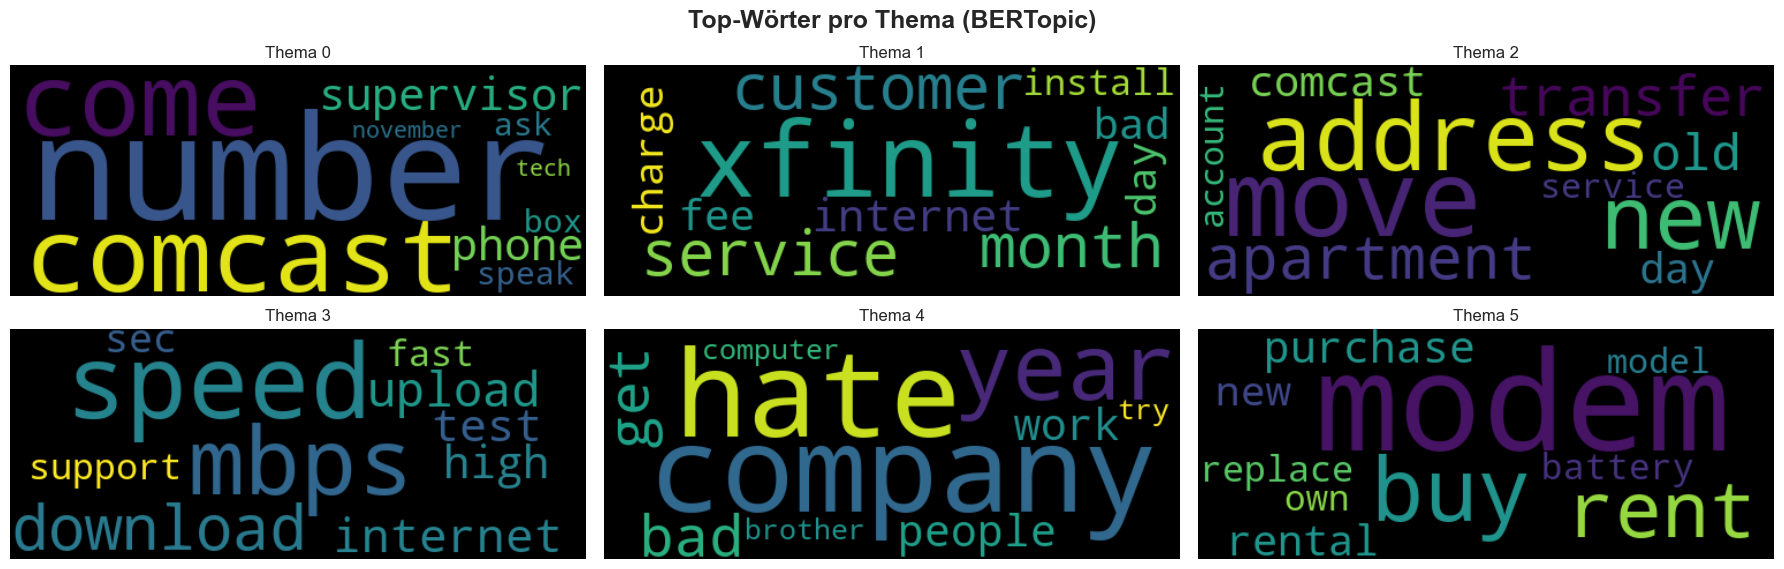

In [30]:
# ============================================================
# Merkmalsdarstellung: BERTopic-Modell
# ============================================================

# *******************************************************************
# Top-Wörter pro Thema (BERTopic) - Tabulare Ausgabe
# *******************************************************************
# Return top n words for a specific topic and their c-TF-IDF scores.

print("=== Top-Wörter pro Thema (BERTopic) ===")

# Alle Themen 1-5 ausgeben (Top-5 Wörter pro Thema)
# for topic_id in range(0, 6):
#    topic_words = bertopic_model.get_topic(topic_id)[:5]  # Nur Top-5 Wörter
#    print(f"\nBERTopic {topic_id}:")
#    for word, score in topic_words:
#        print(f"  {word:20s} {score:.4f}")
valid_topic_ids = sorted(
    topic_id for topic_id in set(bertopic_model.topics_)
    if topic_id != -1
)

for topic_id in valid_topic_ids:
    topic_words = bertopic_model.get_topic(topic_id)

    if not topic_words:
        continue

    print(f"\nBERTopic {topic_id}:")
    for word, score in topic_words[:5]:
        print(f"  {word:20s} {score:.4f}")
# *******************************************************************
# Top-Wörter pro Thema (BERTopic) - Visuelle Darstellung (Wortwolken)
# *******************************************************************

from wordcloud import WordCloud
import matplotlib.pyplot as plt

# BERTopic Topics extrahieren (nur valide Topics, nicht -1)
num_words = 10  # Anzahl der Top-Wörter pro Thema
valid_topics = [t for t in bertopic_model.topics_ if t != -1]
num_bertopic_topics = len(set(valid_topics))

# Wortwolken im Gitter
num_display_topics = 5  # Anzahl anzuzeigender Themen
cols = 3
rows = (num_display_topics + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 6, rows * 3))
axes = axes.flatten() if num_bertopic_topics > 1 else [axes]

# Zentrale Überschrift über dem Grid
fig.text(0.5, 0.98, "Top-Wörter pro Thema (BERTopic)\n", fontsize=18, fontweight='bold', ha='center', va='top')

# Nur Topics 1-6 darstellen (Topic 0 oft Rauschen)
topic_counter = 0
for topic_id in range(min(6, len(valid_topics))):
    if topic_id > -1 and topic_counter < num_bertopic_topics:  # Nur positive Topics
        topic_terms = bertopic_model.get_topic(topic_id)[:num_words]
        if topic_terms:
            # Wörter und ihre Gewichte in Dict konvertieren
            topic_dict = {word: score for word, score in topic_terms}
            wc = WordCloud(width=500, height=200, background_color='black', relative_scaling=0.5).generate_from_frequencies(topic_dict)
            axes[topic_counter].imshow(wc, interpolation='bilinear')
            axes[topic_counter].axis('off')
            axes[topic_counter].set_title(f"Thema {topic_id}")
            topic_counter += 1

# Leere Subplots ausblenden
for ax in axes[topic_counter:]:
    ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)  # Platz für die zentrale Überschrift
plt.show()
fig.show()

In [ ]:
# ============================================================
# Merkmalsdarstellung: BERTopic-Modell
# ============================================================

# *******************************************************************
# Wortrelevanzscores (engl. topic word scores)
# *******************************************************************
from IPython.display import display, HTML

fig = bertopic_model.visualize_barchart()

fig_bar = bertopic_model.visualize_barchart()
def show_centered_plotly(fig, width=1200, height=None):
    fig.update_layout(
        width=width,
        height=height,
        autosize=True,
        title={"font": {"size": 22, "family": "Arial Black"}}
    )
    html = fig.to_html(include_plotlyjs="cdn", full_html=False)
    display(HTML(
        f"""
<div style="width: 100%; display: flex; justify-content: center;">
  <div style="max-width: {width}px; width: 100%;">
    {html}
  </div>
</div>
"""
    ))

fig_bar.update_layout(
    title={
        "x": 0.5,
        "xanchor": "center",
        "font": {"size": 20, "family": "Arial Black"}
    }
)
show_centered_plotly(fig_bar, width=1200, height=500)
# Topic 0 ist ein Sammel-Topic für seltene Wörter, die in den anderen Topics nicht stark vertreten sind. Es enthält viele allgemeine Wörter, die in vielen Dokumenten vorkommen, aber nicht spezifisch fuer ein bestimmtes Thema sind (Rauschen).

# *******************************************************************
# Topics pro Klasse (engl. topics per class)
# *******************************************************************
from IPython.display import display, HTML
import pandas as pd
import numpy as np

# Klassenvariable  (rating oder state)
class_column = "state"

# Datenbasis mit Klasseninformation vorbereiten (nur text_cleaned)
docs_for_class = df["text_cleaned"].astype(str).tolist()
classes = df2[class_column].astype(str).fillna("Unknown").tolist()

# Sicherheitscheck: gleiche Länge von Dokumenten und Klassen
if len(docs_for_class) != len(classes):
    raise ValueError(
        f"Längen stimmen nicht überein: docs={len(docs_for_class)} vs classes={len(classes)}"
    )
# Topics pro Klasse berechnen
topics_per_class = bertopic_model.topics_per_class(
    docs=docs_for_class,
    classes=classes
)

# Nur gewünschte Topics anzeigen (nur Topic -1 ausblenden, Topic 0 wird angezeigt)
valid_topics = sorted(
    t for t in topics_per_class["Topic"].unique().tolist()
    if t != -1
)

# Visualisierung erzeugen und anzeigen
if not valid_topics:
    print("Keine Topics außer -1 vorhanden. Bitte BERTopic-Training anpassen.")
else:
    fig_topics_per_class = bertopic_model.visualize_topics_per_class(
        topics_per_class,
        topics=valid_topics
    )
    fig_topics_per_class.update_layout(
        autosize=True,
        height=650,
        width=1200,
        title={
            "x": 0.5,
            "xanchor": "center",
            "font": {
                "size": 22,
                "family": "Arial Black"
            }
        }
    )

    html = fig_topics_per_class.to_html(include_plotlyjs=True, full_html=False)
    display(HTML("""
<div style="width: 100%; display: flex; justify-content: center;">
  <div style="max-width: 1200px; width: 100%;">
""" + html + """
  </div>
</div>
"""))

# *******************************************************************
# Hierarchische Clusterung (engl. hierarchical clustering)
# *******************************************************************

fig_hierarchy = bertopic_model.visualize_hierarchy()
show_centered_plotly(fig_hierarchy, width=1200, height=700)

# *******************************************************************
# Themenentfernungskarte (engl. intertopic distance map)
# *******************************************************************

from IPython.display import display, HTML

fig_topics = bertopic_model.visualize_topics()
fig_topics.update_layout(
    autosize=True,
    height=600,
    width=1200,
    title={
        "font": {
            "size": 22,
            "family": "Arial Black"
        }
    }
)

html = fig_topics.to_html(include_plotlyjs="cdn", full_html=False)
display(HTML("""
<div style="width: 100%; display: flex; justify-content: center;">
  <div style="max-width: 1200px; width: 100%;">
""" + html + """
  </div>
</div>
"""))


# *******************************************************************
# Dokumente und Topics (engl. documents and topics)
# *******************************************************************

fig_docs = bertopic_model.visualize_documents(
    docs=df2['text'].tolist(),
    embeddings=embeddings,
    topics=topics
 )
show_centered_plotly(fig_docs, width=1200, height=700)

# *******************************************************************
# Term-Bewertungsrückgang pro Thema (engl. term scores decline per topic)
# *******************************************************************

fig_rank = bertopic_model.visualize_term_rank()
show_centered_plotly(fig_rank, width=1200, height=500)

# Visualize the ranks of all terms across all topics.
# Each topic is represented by a set of words. These words, however, do not all equally represent the topic. This visualization shows how many words are needed to represent a topic and at which point the beneficial effect of adding words starts to decline.

# *******************************************************************
# Themenentwicklung über die Zeit (engl. topic over time)
# *******************************************************************


# Choroplethenkarte (engl. choropleth map)
Durch die Choroplethenkarte erfolgte eine Kombination von Input- und Output-Merkmalen in einer hybriden Präsentationsform. 

In [32]:
# ============================================================
# Choroplethenkarte (engl. choropleth map) 
# ============================================================

import plotly.graph_objects as go
import plotly.io as pio
import pandas as pd
import numpy as np
from IPython.display import display, HTML


# Datensatz laden
df2 = pd.read_csv('../datasets/complaints_data_cleaned.csv', nrows=MAX_ROWS)
print(f"Datensatz geladen: {len(df2)} Beschwerden")

# Zeitraumberechnung
df2['date'] = pd.to_datetime(df2['posted_on'], format='mixed', errors='coerce')


# *******************************************************************
# Input-Merkmale (pro Bundestaat)
# *******************************************************************

# beobachtete Merkmale (engl. observed features) - (author, posted_on, rating, state).

all_states = [
    'AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA',
    'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD',
    'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ',
    'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC',
    'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY', 'DC',
]

rating_by_state = df2.groupby('state')['rating'].agg(['mean', 'std']).reset_index()
rating_by_state.columns = ['state', 'avg_rating', 'std_rating']

complaints_by_state = df2.groupby('state').size().reset_index(name='complaints')

## konstruierte/entwickelte Merkmale (engl. engineered features)
### Beschwerdezeitraum
time_by_state = df2.groupby('state')['date'].agg(['min', 'max']).reset_index()
time_by_state['timespan_days'] = (time_by_state['max'] - time_by_state['min']).dt.days
time_by_state['timespan_str'] = time_by_state.apply(
    lambda x: f"{x['min'].strftime('%Y-%m-%d')} bis {x['max'].strftime('%Y-%m-%d')}" 
    if pd.notna(x['min']) and pd.notna(x['max']) else "Keine Daten",
    axis=1,
)
### Textlänge (Zeichenanzahl)
df2['text_length'] = df2['text'].astype(str).str.len()
text_stats_by_state = df2.groupby('state')['text_length'].agg(['mean']).reset_index()
text_stats_by_state.columns = ['state', 'avg_text_length']

## Beschwerdehäufung (pro Monat)
df2['month'] = df2['date'].dt.month
df2['month_name'] = df2['date'].dt.month_name()

def get_most_common_month(state_group):
    if len(state_group) == 0 or state_group['month_name'].isna().all():
        return pd.Series({'most_common_month': 'Keine Daten'})
    month_counts = state_group['month_name'].value_counts()
    if len(month_counts) > 0:
        return pd.Series({'most_common_month': month_counts.index[0]})
    return pd.Series({'most_common_month': 'Keine Daten'})

month_by_state = df2.groupby('state').apply(get_most_common_month, include_groups=False)).reset_index()

# *******************************************************************
# Output-Merkmale - (Themen)
# *******************************************************************

df2['topic'] = topics
df2['topic_prob'] = probs if probs.ndim == 1 else probs.max(axis=1)

# Dominantes Thema pro Bundesstaat
def get_dominant_topic(state_group):
    if len(state_group) == 0:
        return pd.Series({
            'topic_label': 'Keine Daten',
            'topic_prob_avg': 0.0,
            'num_topics': 0
        })
    
    # Topic -1 (Outlier/Noise) und Topic 0 (allgemeine Wörter) ausfiltern
    state_group_filtered = state_group[(state_group['topic'] != -1) & (state_group['topic'] != 0)]
    
    if len(state_group_filtered) == 0:
        return pd.Series({
            'topic_label': 'Keine relevanten Topics',
            'topic_prob_avg': 0.0,
            'num_topics': 0
        })
    
    state_dist = state_group_filtered['topic'].value_counts()
    dominant_topic = state_dist.index[0]
    
    topic_words = bertopic_model.get_topic(int(dominant_topic))
    if topic_words:
        top_words = ', '.join([word for word, _ in topic_words[:3]])
        topic_label = f"{int(dominant_topic)} ({top_words})"
    else:
        topic_label = f"{int(dominant_topic)}"
    
    avg_prob = state_group_filtered['topic_prob'].mean()
    num_topics = state_group_filtered['topic'].nunique()
    
    return pd.Series({
        'topic_label': topic_label,
        'topic_prob_avg': round(avg_prob, 3),
        'num_topics': int(num_topics)
    })

dominant_topics = (
    df2[df2["topic"].notna()]
    .groupby("state")
    .apply(get_dominant_topic, include_groups=False)
    .reset_index()
)

# *******************************************************************
# Merkmalskombination aus Input- und Output-Merkmalen
# *******************************************************************

combined_data = pd.DataFrame({'state': all_states})
combined_data = combined_data.merge(complaints_by_state, on='state', how='left')
combined_data = combined_data.merge(rating_by_state, on='state', how='left')
combined_data = combined_data.merge(time_by_state[['state', 'timespan_str']], on='state', how='left')
combined_data = combined_data.merge(text_stats_by_state, on='state', how='left')
combined_data = combined_data.merge(month_by_state, on='state', how='left')
combined_data = combined_data.merge(dominant_topics, on='state', how='left')

# Fehlwerte füllen
combined_data['complaints'] = combined_data['complaints'].fillna(0).astype(int)
combined_data['avg_rating'] = combined_data['avg_rating'].fillna(0)
combined_data['std_rating'] = combined_data['std_rating'].fillna(0)
combined_data['timespan_str'] = combined_data['timespan_str'].fillna('Keine Daten')
combined_data['avg_text_length'] = combined_data['avg_text_length'].fillna(0)
combined_data['most_common_month'] = combined_data['most_common_month'].fillna('Keine Daten')
combined_data['topic_label'] = combined_data['topic_label'].fillna('Keine Daten')
combined_data['num_topics'] = combined_data['num_topics'].fillna(0).astype(int)

# *******************************************************************
# Choroplethenkarte (Hover-Text)
# *******************************************************************

# Hovertext
hover_text = []
for _, row in combined_data.iterrows():
    if row['complaints'] > 0:
        text = (
            f"<b>{row['state']}</b><br><br>"
            f"<b><u>Input-Features:</u></b><br>"
                f"<b>→ beobachtete Merkmale</b> (observed features)<br>"
                    f"&nbsp;&nbsp;&nbsp;&nbsp;• Beschwerden:  {row['complaints']}<br>"
                    f"&nbsp;&nbsp;&nbsp;&nbsp;• Ø Rating:  {row['avg_rating']:.2f}<br>"
                    f"&nbsp;&nbsp;&nbsp;&nbsp;• Zeitraum:  {row['timespan_str']}<br>"
                f"<b>→ konstruierte Merkmale</b> (engineered features)<br>"
                    f"&nbsp;&nbsp;&nbsp;&nbsp;• Beschwerdehäufung:  {row['most_common_month']}<br>"
                    f"&nbsp;&nbsp;&nbsp;&nbsp;• Ø Textlänge:  {row['avg_text_length']:.0f} Zeichen<br><br>"
            f"<b><u>Output-Features:</u></b><br>"
                f"<b>→ Cluster</b><br>"
                    f"&nbsp;&nbsp;&nbsp;&nbsp;• Themenanzahl:  {row['num_topics']}<br>"
                    f"&nbsp;&nbsp;&nbsp;&nbsp;• Hauptthema:      {row['topic_label']}<br><br>"
        )
    else:
        text = f"<b>{row['state']}</b><br>Keine Daten"
    hover_text.append(text)
    
combined_data['hover_text'] = hover_text


# Karten-Body
def show_centered_plotly(fig, max_width=1200):
    html = fig.to_html(include_plotlyjs="cdn", full_html=False, config={"responsive": True})
    display(HTML(
        f"""
<div style=\"width: 100%; display: flex; justify-content: center;\">
  <div style=\"width: 100%; max-width: {max_width}px;\">
    {html}
  </div>
</div>
"""
    ))

fig = go.Figure(data=go.Choropleth(
    locations=combined_data['state'],
    z=combined_data['complaints'].astype(float),
    text=combined_data['hover_text'],
    locationmode='USA-states',
    colorscale=[[0, "#499615"], [0.25, "#fbde03"], [0.5, "#fbb503"], [1, '#8B0000']],
    colorbar=dict(title="Beschwerden"),
    hovertemplate='%{text}<extra></extra>'
))

fig.update_layout(
    title=dict(
        text='<b>Choroplethenkarte</b><br><sub>Beschwerden nach US-Bundesstaat</sub>',
        x=0.5,
        xanchor='center'
    ),
    geo=dict(scope='usa', projection_type='albers usa'),
    autosize=True,
    height=700,
    margin=dict(l=0, r=0, t=100, b=50)
)

show_centered_plotly(fig)

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 163)

# Modelldarstellungen (engl. modell visualizations)
Die Modellvisualisierung erfolgt durch Ausgabe der im Rahmen der Modellqualitätsmessung ermittelten Metriken.

In [33]:
# ============================================================
# Modelldarstellungen (engl. model visualizations)
# ============================================================

# *******************************************************************
# Kohärenzwerte (engl. coherence scores)
# *******************************************************************

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# LDA-Kohärenzwerte (engl. LDA coherence score)
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

print("=== Kohärenzwerte (engl. coherence scores) ===\n")

if 'coherence_lda' in globals():
    print(f"Coherence Score (LDA):          {coherence_lda:.4f}\n")
else:
    print("Coherence Score (LDA):      nicht verfügbar (bitte die Kohärenz-Zelle für LDA zuerst ausführen)")
    
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# BERTopic-Kohärenzwert (engl. BERTopic coherence score)
# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

if 'coherence_bertopic' in globals():
    print(f"Coherence Score (BERTopic):     {coherence_bertopic:.4f}\n")
else:
    print("Coherence Score (BERTopic): nicht verfügbar (bitte die Kohärenz-Zelle für BERTopic zuerst ausführen)")

# *******************************************************************
# Themenvielfalt (engl. topic diversity)
# *******************************************************************
print("\n=== Themenvielfalt (engl. topic diversity) ===\n")
print(f"Topic Diversity (LDA):        {diversity_lda:.4f}")
print(f"\nTopic Diversity (BERTopic):   {diversity_bertopic:.4f}\n")

=== Kohärenzwerte (engl. coherence scores) ===

Coherence Score (LDA):          0.4590

Coherence Score (BERTopic):     0.3831


=== Themenvielfalt (engl. topic diversity) ===

Topic Diversity (LDA):        0.8167

Topic Diversity (BERTopic):   0.6056

